In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Working folder banano hocche Drive-e, jate dataset o output shobkichu save thake
import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/dataset', exist_ok=True)
os.makedirs(f'{PROJECT_DIR}/outputs', exist_ok=True)
print("Project dir ready:", PROJECT_DIR)

Mounted at /content/drive
Project dir ready: /content/drive/MyDrive/OCT_C8_Project


In [ ]:
import os

# --- Kaggle new-style API token setup ---
os.makedirs('/root/.kaggle', exist_ok=True)

# Ekhane tomar NIJER (notun generate kora) token ta boso:
KAGGLE_TOKEN = "KGAT_fad969bdceb240ec5b6c7465b4bec391"   # <-- eikhane token ta paste korbe

with open('/root/.kaggle/access_token', 'w') as f:
    f.write(KAGGLE_TOKEN)

os.chmod('/root/.kaggle/access_token', 0o600)

# Environment variable hisebeo set kore rakha bhalo (double safety)
os.environ['KAGGLE_API_TOKEN'] = KAGGLE_TOKEN

# --- Install kaggle package ---
!pip install -q kaggle

# --- Download dataset directly into Drive folder ---
!kaggle datasets download -d obulisainaren/retinal-oct-c8 -p "{PROJECT_DIR}/dataset" --unzip

print("Download complete. Files:")
!ls "{PROJECT_DIR}/dataset"

^C
Download complete. Files:
README.md  RetinalOCT_Dataset


In [ ]:
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

In [ ]:
dataset_root = f'{PROJECT_DIR}/dataset'

for split in ['train', 'val', 'test']:
    split_path = os.path.join(dataset_root, split)
    if os.path.exists(split_path):
        classes = os.listdir(split_path)
        print(f"\n{split.upper()} — {len(classes)} classes")
        for c in classes:
            n = len(os.listdir(os.path.join(split_path, c)))
            print(f"  {c}: {n} images")

In [ ]:
import cv2
import numpy as np

IMG_SIZE = (224, 224)

def load_and_preprocess(img_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE)
    img = img.astype(np.float32) / 255.0
    return img

In [ ]:
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

# Confirm করো ঠিক আছে কিনা
import os
print(os.listdir(dataset_root))  # ['test', 'train', 'val'] আসা উচিত

['test', 'train', 'val']


In [ ]:
!pip install -q imagehash

import imagehash
from PIL import Image
import pandas as pd
from itertools import combinations

def compute_hashes(split_path):
    records = []
    for class_name in os.listdir(split_path):
        class_dir = os.path.join(split_path, class_name)
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            try:
                h = imagehash.phash(Image.open(fpath))
                records.append({'path': fpath, 'class': class_name, 'hash': h})
            except Exception as e:
                print("Skip:", fpath, e)
    return records

train_hashes = compute_hashes(os.path.join(dataset_root, 'train'))
val_hashes   = compute_hashes(os.path.join(dataset_root, 'val'))
test_hashes  = compute_hashes(os.path.join(dataset_root, 'test'))

print(f"Train: {len(train_hashes)}, Val: {len(val_hashes)}, Test: {len(test_hashes)}")

# --- Cross-split near-duplicate check ---
HASH_THRESHOLD = 5  # hamming distance; kom hole strict match, beshi hole loose

def find_leaks(set_a, set_b, name_a, name_b, threshold=HASH_THRESHOLD):
    leaks = []
    for a in set_a:
        for b in set_b:
            dist = a['hash'] - b['hash']
            if dist <= threshold:
                leaks.append({
                    f'{name_a}_path': a['path'], f'{name_a}_class': a['class'],
                    f'{name_b}_path': b['path'], f'{name_b}_class': b['class'],
                    'hamming_distance': dist
                })
    return leaks

leaks_train_val  = find_leaks(train_hashes, val_hashes, 'train', 'val')
leaks_train_test = find_leaks(train_hashes, test_hashes, 'train', 'test')
leaks_val_test   = find_leaks(val_hashes, test_hashes, 'val', 'test')

print(f"Train-Val leaks: {len(leaks_train_val)}")
print(f"Train-Test leaks: {len(leaks_train_test)}")
print(f"Val-Test leaks: {len(leaks_val_test)}")

# --- Save reports to Drive ---
pd.DataFrame(leaks_train_val).to_csv(f'{PROJECT_DIR}/outputs/leaks_train_val.csv', index=False)
pd.DataFrame(leaks_train_test).to_csv(f'{PROJECT_DIR}/outputs/leaks_train_test.csv', index=False)
pd.DataFrame(leaks_val_test).to_csv(f'{PROJECT_DIR}/outputs/leaks_val_test.csv', index=False)

print("Reports saved to Drive outputs folder.")

Train: 18400, Val: 2800, Test: 2800
Train-Val leaks: 240
Train-Test leaks: 210
Val-Test leaks: 16
Reports saved to Drive outputs folder.


In [ ]:
import os

dataset_root = f'{PROJECT_DIR}/dataset'

# Top-level dekhi
print("Top level:", os.listdir(dataset_root))

# RetinalOCT_Dataset er bhitore ki ache dekhi
inner_path = os.path.join(dataset_root, 'RetinalOCT_Dataset')
if os.path.exists(inner_path):
    print("\nInside RetinalOCT_Dataset:", os.listdir(inner_path))

Top level: ['README.md', 'RetinalOCT_Dataset']

Inside RetinalOCT_Dataset: ['RetinalOCT_Dataset']


In [ ]:
inner_path2 = os.path.join(dataset_root, 'RetinalOCT_Dataset', 'RetinalOCT_Dataset')
print("Inside second RetinalOCT_Dataset:", os.listdir(inner_path2))


Inside second RetinalOCT_Dataset: ['test', 'train', 'val']


In [ ]:
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

In [ ]:
for split in ['train', 'val', 'test']:
    split_path = os.path.join(dataset_root, split)
    if os.path.exists(split_path):
        classes = os.listdir(split_path)
        print(f"\n{split.upper()} — {len(classes)} classes")
        for c in classes:
            n = len(os.listdir(os.path.join(split_path, c)))
            print(f"  {c}: {n} images")


TRAIN — 8 classes
  AMD: 2300 images
  CNV: 2300 images
  CSR: 2300 images
  DME: 2300 images
  DR: 2300 images
  DRUSEN: 2300 images
  MH: 2300 images
  NORMAL: 2300 images

VAL — 8 classes
  AMD: 350 images
  CNV: 350 images
  CSR: 350 images
  DME: 350 images
  DR: 350 images
  DRUSEN: 350 images
  MH: 350 images
  NORMAL: 350 images

TEST — 8 classes
  AMD: 350 images
  CNV: 350 images
  CSR: 350 images
  DME: 350 images
  DR: 350 images
  DRUSEN: 350 images
  MH: 350 images
  NORMAL: 350 images


In [ ]:
import imagehash
from PIL import Image
import pandas as pd
import numpy as np
import os

def popcount64(x):
    x = x - ((x >> np.uint64(1)) & np.uint64(0x5555555555555555))
    x = (x & np.uint64(0x3333333333333333)) + ((x >> np.uint64(2)) & np.uint64(0x3333333333333333))
    x = (x + (x >> np.uint64(4))) & np.uint64(0x0f0f0f0f0f0f0f0f)
    return (x * np.uint64(0x0101010101010101)) >> np.uint64(56)

def compute_hashes_by_class(split_path):
    """class_name -> (list of paths, numpy uint64 array of phash-as-int)"""
    data = {}
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join(split_path, class_name)
        paths, hashes = [], []
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            try:
                h = imagehash.phash(Image.open(fpath))
                paths.append(fpath)
                hashes.append(int(str(h), 16))
            except Exception as e:
                print("Skip:", fpath, e)
        data[class_name] = (paths, np.array(hashes, dtype=np.uint64))
        print(f"  {class_name}: {len(paths)} hashed")
    return data

print("Hashing TRAIN...")
train_data = compute_hashes_by_class(os.path.join(dataset_root, 'train'))
print("Hashing VAL...")
val_data = compute_hashes_by_class(os.path.join(dataset_root, 'val'))
print("Hashing TEST...")
test_data = compute_hashes_by_class(os.path.join(dataset_root, 'test'))
print("All hashing done.")

Hashing TRAIN...
  AMD: 2300 hashed
  CNV: 2300 hashed
  CSR: 2300 hashed
  DME: 2300 hashed
  DR: 2300 hashed
  DRUSEN: 2300 hashed
  MH: 2300 hashed
  NORMAL: 2300 hashed
Hashing VAL...
  AMD: 350 hashed
  CNV: 350 hashed
  CSR: 350 hashed
  DME: 350 hashed
  DR: 350 hashed
  DRUSEN: 350 hashed
  MH: 350 hashed
  NORMAL: 350 hashed
Hashing TEST...
  AMD: 350 hashed
  CNV: 350 hashed
  CSR: 350 hashed
  DME: 350 hashed
  DR: 350 hashed
  DRUSEN: 350 hashed
  MH: 350 hashed
  NORMAL: 350 hashed
All hashing done.


In [ ]:
HASH_THRESHOLD = 5  # hamming distance; komale strict, barale loose match

def find_leaks_vectorized(data_a, data_b, name_a, name_b, threshold=HASH_THRESHOLD):
    leaks = []
    classes = sorted(set(data_a.keys()) & set(data_b.keys()))
    for cls in classes:
        paths_a, hashes_a = data_a[cls]
        paths_b, hashes_b = data_b[cls]
        if len(hashes_a) == 0 or len(hashes_b) == 0:
            continue
        xor_matrix = hashes_a[:, None] ^ hashes_b[None, :]
        dist_matrix = popcount64(xor_matrix)
        idx_a, idx_b = np.where(dist_matrix <= threshold)
        for i, j in zip(idx_a, idx_b):
            leaks.append({
                f'{name_a}_path': paths_a[i],
                f'{name_b}_path': paths_b[j],
                'class': cls,
                'hamming_distance': int(dist_matrix[i, j])
            })
    return leaks

print("Checking Train-Val...")
leaks_train_val  = find_leaks_vectorized(train_data, val_data, 'train', 'val')
print("Checking Train-Test...")
leaks_train_test = find_leaks_vectorized(train_data, test_data, 'train', 'test')
print("Checking Val-Test...")
leaks_val_test   = find_leaks_vectorized(val_data, test_data, 'val', 'test')

print(f"\nTrain-Val leaks: {len(leaks_train_val)}")
print(f"Train-Test leaks: {len(leaks_train_test)}")
print(f"Val-Test leaks: {len(leaks_val_test)}")

pd.DataFrame(leaks_train_val).to_csv(f'{PROJECT_DIR}/outputs/leaks_train_val.csv', index=False)
pd.DataFrame(leaks_train_test).to_csv(f'{PROJECT_DIR}/outputs/leaks_train_test.csv', index=False)
pd.DataFrame(leaks_val_test).to_csv(f'{PROJECT_DIR}/outputs/leaks_val_test.csv', index=False)

print("\nSaved leak reports to Drive outputs folder.")

Checking Train-Val...
Checking Train-Test...
Checking Val-Test...

Train-Val leaks: 175
Train-Test leaks: 158
Val-Test leaks: 12

Saved leak reports to Drive outputs folder.


In [ ]:
from skimage.metrics import structural_similarity as ssim
import cv2
import pandas as pd

SSIM_THRESHOLD = 0.90  # egerchay high hole strict; ei value paper e report korte hobe

def verify_with_ssim(csv_path, col_a, col_b):
    df = pd.read_csv(csv_path)
    if len(df) == 0:
        df['ssim_score'] = []
        df['confirmed_duplicate'] = []
        return df

    ssim_scores = []
    for _, row in df.iterrows():
        img_a = cv2.imread(row[col_a], cv2.IMREAD_GRAYSCALE)
        img_b = cv2.imread(row[col_b], cv2.IMREAD_GRAYSCALE)
        # Same size e resize kora hocche fair comparison er jonne
        img_b = cv2.resize(img_b, (img_a.shape[1], img_a.shape[0]))
        score = ssim(img_a, img_b)
        ssim_scores.append(score)

    df['ssim_score'] = ssim_scores
    df['confirmed_duplicate'] = df['ssim_score'] >= SSIM_THRESHOLD
    return df

print("Verifying Train-Val leaks...")
tv_df = verify_with_ssim(f'{PROJECT_DIR}/outputs/leaks_train_val.csv', 'train_path', 'val_path')
print("Verifying Train-Test leaks...")
tt_df = verify_with_ssim(f'{PROJECT_DIR}/outputs/leaks_train_test.csv', 'train_path', 'test_path')
print("Verifying Val-Test leaks...")
vt_df = verify_with_ssim(f'{PROJECT_DIR}/outputs/leaks_val_test.csv', 'val_path', 'test_path')

tv_df.to_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv', index=False)
tt_df.to_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv', index=False)
vt_df.to_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv', index=False)

print(f"\nTrain-Val: {tv_df['confirmed_duplicate'].sum()} / {len(tv_df)} confirmed")
print(f"Train-Test: {tt_df['confirmed_duplicate'].sum()} / {len(tt_df)} confirmed")
print(f"Val-Test: {vt_df['confirmed_duplicate'].sum()} / {len(vt_df)} confirmed")

Verifying Train-Val leaks...
Verifying Train-Test leaks...
Verifying Val-Test leaks...

Train-Val: 29 / 175 confirmed
Train-Test: 19 / 158 confirmed
Val-Test: 1 / 12 confirmed


In [ ]:
import pandas as pd

tv_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv')
tt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')

tv_confirmed = tv_df[tv_df['confirmed_duplicate'] == True]
tt_confirmed = tt_df[tt_df['confirmed_duplicate'] == True]
vt_confirmed = vt_df[vt_df['confirmed_duplicate'] == True]

remove_from_val  = set(tv_confirmed['val_path'])
remove_from_test = set(tt_confirmed['test_path']) | set(vt_confirmed['test_path'])

print(f"Images to remove from VAL: {len(remove_from_val)}")
print(f"Images to remove from TEST: {len(remove_from_test)}")

# Log e save kore rakhlam paper-e report korar jonne
pd.DataFrame({'removed_val_path': list(remove_from_val)}).to_csv(
    f'{PROJECT_DIR}/outputs/removed_from_val.csv', index=False)
pd.DataFrame({'removed_test_path': list(remove_from_test)}).to_csv(
    f'{PROJECT_DIR}/outputs/removed_from_test.csv', index=False)

Images to remove from VAL: 28
Images to remove from TEST: 20


In [ ]:
def build_file_label_list(split_path, exclude_set=None):
    """Returns list of (filepath, class_label) tuples"""
    exclude_set = exclude_set or set()
    data = []
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join(split_path, class_name)
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            if fpath not in exclude_set:
                data.append((fpath, class_name))
    return data

# --- Condition A: original, untouched ---
condA_train = build_file_label_list(os.path.join(dataset_root, 'train'))
condA_val   = build_file_label_list(os.path.join(dataset_root, 'val'))
condA_test  = build_file_label_list(os.path.join(dataset_root, 'test'))

# --- Condition B: deduplicated ---
condB_train = build_file_label_list(os.path.join(dataset_root, 'train'))  # train unchanged
condB_val   = build_file_label_list(os.path.join(dataset_root, 'val'), exclude_set=remove_from_val)
condB_test  = build_file_label_list(os.path.join(dataset_root, 'test'), exclude_set=remove_from_test)

print("=== Condition A (Original) ===")
print(f"Train: {len(condA_train)}, Val: {len(condA_val)}, Test: {len(condA_test)}")

print("\n=== Condition B (Deduplicated) ===")
print(f"Train: {len(condB_train)}, Val: {len(condB_val)}, Test: {len(condB_test)}")

# --- Per-class breakdown for Condition B (paper-e table hisebe lagbe) ---
from collections import Counter
print("\nCondition B - Val class distribution:", Counter([c for _, c in condB_val]))
print("Condition B - Test class distribution:", Counter([c for _, c in condB_test]))

=== Condition A (Original) ===
Train: 18400, Val: 2800, Test: 2800

=== Condition B (Deduplicated) ===
Train: 18400, Val: 2772, Test: 2780

Condition B - Val class distribution: Counter({'AMD': 350, 'CSR': 350, 'DR': 350, 'MH': 350, 'NORMAL': 349, 'CNV': 344, 'DME': 341, 'DRUSEN': 338})
Condition B - Test class distribution: Counter({'AMD': 350, 'CSR': 350, 'DR': 350, 'MH': 350, 'NORMAL': 350, 'DME': 348, 'CNV': 344, 'DRUSEN': 338})


In [ ]:
import pickle

splits = {
    'condA_train': condA_train, 'condA_val': condA_val, 'condA_test': condA_test,
    'condB_train': condB_train, 'condB_val': condB_val, 'condB_test': condB_test,
}

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'wb') as f:
    pickle.dump(splits, f)

print("Saved split_lists.pkl — Condition A & B file lists ready for training.")

Saved split_lists.pkl — Condition A & B file lists ready for training.


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        label = class_to_idx[class_name]
        return img, label

# --- Train transform: resize + light augmentation ---
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# --- Val/Test transform: resize only, no augmentation ---
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_model(num_classes=8):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels)

def run_experiment(train_list, val_list, test_list, seed, epochs=10, batch_size=32, lr=1e-4):
    set_seed(seed)
    train_ds = OCTDataset(train_list, transform=train_transform)
    val_ds   = OCTDataset(val_list, transform=eval_transform)
    test_ds  = OCTDataset(test_list, transform=eval_transform)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_model(num_classes=len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    best_val_acc = 0
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _ = evaluate(model, val_loader)
        print(f"  Seed {seed} | Epoch {epoch+1}/{epochs} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")
        best_val_acc = max(best_val_acc, val_acc)

    test_acc, preds, labels = evaluate(model, test_loader)
    print(f"  Seed {seed} | FINAL TEST ACC = {test_acc:.4f}")
    return test_acc, preds, labels

In [ ]:
import pickle

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)

SEEDS = [42, 123, 2024]
EPOCHS = 10   # dataset boro hole time lagbe, dorkar hole kome barate paro

results = {'condition': [], 'seed': [], 'test_acc': []}
all_preds_labels = {}

for condition, (train_l, val_l, test_l) in [
    ('A_original', (splits['condA_train'], splits['condA_val'], splits['condA_test'])),
    ('B_deduplicated', (splits['condB_train'], splits['condB_val'], splits['condB_test'])),
]:
    print(f"\n{'='*50}\nRunning Condition {condition}\n{'='*50}")
    for seed in SEEDS:
        start = time.time()
        test_acc, preds, labels = run_experiment(train_l, val_l, test_l, seed, epochs=EPOCHS)
        elapsed = time.time() - start
        print(f"  Time: {elapsed/60:.1f} min")

        results['condition'].append(condition)
        results['seed'].append(seed)
        results['test_acc'].append(test_acc)
        all_preds_labels[f'{condition}_seed{seed}'] = (preds, labels)

import pandas as pd
results_df = pd.DataFrame(results)
results_df.to_csv(f'{PROJECT_DIR}/outputs/experiment_results.csv', index=False)

with open(f'{PROJECT_DIR}/outputs/preds_labels.pkl', 'wb') as f:
    pickle.dump(all_preds_labels, f)

print("\n\n=== SUMMARY ===")
print(results_df.groupby('condition')['test_acc'].agg(['mean', 'std']))


Running Condition A_original
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 133MB/s]


  Seed 42 | Epoch 1/10 | train_loss=0.2594 train_acc=0.9113 val_acc=0.9504
  Seed 42 | Epoch 2/10 | train_loss=0.1240 train_acc=0.9586 val_acc=0.9504
  Seed 42 | Epoch 3/10 | train_loss=0.1034 train_acc=0.9667 val_acc=0.9668
  Seed 42 | Epoch 4/10 | train_loss=0.0902 train_acc=0.9695 val_acc=0.9664
  Seed 42 | Epoch 5/10 | train_loss=0.0807 train_acc=0.9729 val_acc=0.9636
  Seed 42 | Epoch 6/10 | train_loss=0.0714 train_acc=0.9772 val_acc=0.9750
  Seed 42 | Epoch 7/10 | train_loss=0.0656 train_acc=0.9782 val_acc=0.9493
  Seed 42 | Epoch 8/10 | train_loss=0.0608 train_acc=0.9788 val_acc=0.9704
  Seed 42 | Epoch 9/10 | train_loss=0.0591 train_acc=0.9802 val_acc=0.9700
  Seed 42 | Epoch 10/10 | train_loss=0.0461 train_acc=0.9842 val_acc=0.9714
  Seed 42 | FINAL TEST ACC = 0.9711
  Time: 31.4 min
  Seed 123 | Epoch 1/10 | train_loss=0.2631 train_acc=0.9095 val_acc=0.9486
  Seed 123 | Epoch 2/10 | train_loss=0.1280 train_acc=0.9573 val_acc=0.9632
  Seed 123 | Epoch 3/10 | train_loss=0.1057 

KeyboardInterrupt: 

In [ ]:
import pandas as pd

condA_results = pd.DataFrame({
    'condition': ['A_original', 'A_original'],
    'seed': [42, 123],
    'test_acc': [0.9711, 0.9754]
})
condA_results.to_csv(f'{PROJECT_DIR}/outputs/condA_results.csv', index=False)
print("Saved so far:", condA_results)

Saved so far:     condition  seed  test_acc
0  A_original    42    0.9711
1  A_original   123    0.9754


In [ ]:
import pickle, time, pandas as pd

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)

EPOCHS = 10
results_path = f'{PROJECT_DIR}/outputs/condA_results.csv'

# --- Resume Condition A: baki thaka seed 2024 ---
results_df = pd.read_csv(results_path)  # already 42,123 ache

for seed in [42, 123, 2024]:
    if ((results_df['condition'] == 'A_original') & (results_df['seed'] == seed)).any():
        print(f"Seed {seed} (A) already done, skipping.")
        continue
    print(f"Running Condition A, seed {seed}...")
    start = time.time()
    test_acc, preds, labels = run_experiment(
        splits['condA_train'], splits['condA_val'], splits['condA_test'], seed, epochs=EPOCHS
    )
    print(f"  Time: {(time.time()-start)/60:.1f} min | Test acc: {test_acc:.4f}")
    new_row = pd.DataFrame([{'condition': 'A_original', 'seed': seed, 'test_acc': test_acc}])
    results_df = pd.concat([results_df, new_row], ignore_index=True)
    results_df.to_csv(results_path, index=False)
    with open(f'{PROJECT_DIR}/outputs/preds_A_seed{seed}.pkl', 'wb') as f:
        pickle.dump((preds, labels), f)

print("\nCondition A fully done:")
print(results_df)

Seed 42 (A) already done, skipping.
Seed 123 (A) already done, skipping.
Running Condition A, seed 2024...
  Seed 2024 | Epoch 1/10 | train_loss=0.2537 train_acc=0.9141 val_acc=0.9550
  Seed 2024 | Epoch 2/10 | train_loss=0.1259 train_acc=0.9582 val_acc=0.9611
  Seed 2024 | Epoch 3/10 | train_loss=0.1037 train_acc=0.9658 val_acc=0.9650
  Seed 2024 | Epoch 4/10 | train_loss=0.0918 train_acc=0.9692 val_acc=0.9664
  Seed 2024 | Epoch 5/10 | train_loss=0.0798 train_acc=0.9729 val_acc=0.9514
  Seed 2024 | Epoch 6/10 | train_loss=0.0756 train_acc=0.9765 val_acc=0.9696
  Seed 2024 | Epoch 7/10 | train_loss=0.0661 train_acc=0.9786 val_acc=0.9661
  Seed 2024 | Epoch 8/10 | train_loss=0.0583 train_acc=0.9810 val_acc=0.9639
  Seed 2024 | Epoch 9/10 | train_loss=0.0591 train_acc=0.9797 val_acc=0.9689
  Seed 2024 | Epoch 10/10 | train_loss=0.0504 train_acc=0.9833 val_acc=0.9679
  Seed 2024 | FINAL TEST ACC = 0.9754
  Time: 30.2 min | Test acc: 0.9754

Condition A fully done:
    condition  seed  te

In [ ]:
import pickle, time, pandas as pd

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)

SEEDS = [42, 123, 2024]
EPOCHS = 10

results_path = f'{PROJECT_DIR}/outputs/condB_results.csv'

try:
    results_df = pd.read_csv(results_path)
except FileNotFoundError:
    results_df = pd.DataFrame(columns=['condition', 'seed', 'test_acc'])

print("Running Condition B_deduplicated")
for seed in SEEDS:
    if ((results_df['condition'] == 'B_deduplicated') & (results_df['seed'] == seed)).any():
        print(f"  Seed {seed} already done, skipping.")
        continue

    start = time.time()
    test_acc, preds, labels = run_experiment(
        splits['condB_train'], splits['condB_val'], splits['condB_test'], seed, epochs=EPOCHS
    )
    elapsed = time.time() - start
    print(f"  Time: {elapsed/60:.1f} min | Test acc: {test_acc:.4f}")

    new_row = pd.DataFrame([{'condition': 'B_deduplicated', 'seed': seed, 'test_acc': test_acc}])
    results_df = pd.concat([results_df, new_row], ignore_index=True)
    results_df.to_csv(results_path, index=False)

    with open(f'{PROJECT_DIR}/outputs/preds_B_seed{seed}.pkl', 'wb') as f:
        pickle.dump((preds, labels), f)

    print(f"  Saved. Progress: {len(results_df)} runs done so far.")

print("\nCondition B done (or resumed):")
print(results_df)

Running Condition B_deduplicated
  Seed 42 | Epoch 1/10 | train_loss=0.2587 train_acc=0.9102 val_acc=0.9455
  Seed 42 | Epoch 2/10 | train_loss=0.1268 train_acc=0.9577 val_acc=0.9520
  Seed 42 | Epoch 3/10 | train_loss=0.1037 train_acc=0.9666 val_acc=0.9646
  Seed 42 | Epoch 4/10 | train_loss=0.0897 train_acc=0.9699 val_acc=0.9654
  Seed 42 | Epoch 5/10 | train_loss=0.0791 train_acc=0.9729 val_acc=0.9654
  Seed 42 | Epoch 6/10 | train_loss=0.0717 train_acc=0.9757 val_acc=0.9758
  Seed 42 | Epoch 7/10 | train_loss=0.0668 train_acc=0.9768 val_acc=0.9679
  Seed 42 | Epoch 8/10 | train_loss=0.0605 train_acc=0.9801 val_acc=0.9701
  Seed 42 | Epoch 9/10 | train_loss=0.0583 train_acc=0.9807 val_acc=0.9722
  Seed 42 | Epoch 10/10 | train_loss=0.0488 train_acc=0.9821 val_acc=0.9657
  Seed 42 | FINAL TEST ACC = 0.9673
  Time: 31.4 min | Test acc: 0.9673
  Saved. Progress: 1 runs done so far.


/tmp/ipykernel_2752/2053060491.py:30: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results_df = pd.concat([results_df, new_row], ignore_index=True)


  Seed 123 | Epoch 1/10 | train_loss=0.2613 train_acc=0.9105 val_acc=0.9383
  Seed 123 | Epoch 2/10 | train_loss=0.1285 train_acc=0.9578 val_acc=0.9621
  Seed 123 | Epoch 3/10 | train_loss=0.1063 train_acc=0.9649 val_acc=0.9628
  Seed 123 | Epoch 4/10 | train_loss=0.0877 train_acc=0.9711 val_acc=0.9643
  Seed 123 | Epoch 5/10 | train_loss=0.0801 train_acc=0.9749 val_acc=0.9621
  Seed 123 | Epoch 6/10 | train_loss=0.0748 train_acc=0.9750 val_acc=0.9704
  Seed 123 | Epoch 7/10 | train_loss=0.0675 train_acc=0.9772 val_acc=0.9679
  Seed 123 | Epoch 8/10 | train_loss=0.0613 train_acc=0.9803 val_acc=0.9690
  Seed 123 | Epoch 9/10 | train_loss=0.0564 train_acc=0.9805 val_acc=0.9578
  Seed 123 | Epoch 10/10 | train_loss=0.0526 train_acc=0.9822 val_acc=0.9719
  Seed 123 | FINAL TEST ACC = 0.9737
  Time: 30.5 min | Test acc: 0.9737
  Saved. Progress: 2 runs done so far.
  Seed 2024 | Epoch 1/10 | train_loss=0.2540 train_acc=0.9143 val_acc=0.9553
  Seed 2024 | Epoch 2/10 | train_loss=0.1236 train

In [ ]:
import pandas as pd

condA = pd.read_csv(f'{PROJECT_DIR}/outputs/condA_results.csv')
condB = pd.read_csv(f'{PROJECT_DIR}/outputs/condB_results.csv')

combined = pd.concat([condA, condB], ignore_index=True)
combined.to_csv(f'{PROJECT_DIR}/outputs/final_combined_results.csv', index=False)

print(combined)
print("\n=== SUMMARY ===")
print(combined.groupby('condition')['test_acc'].agg(['mean', 'std', 'count']))

        condition  seed  test_acc
0      A_original    42  0.971100
1      A_original   123  0.975400
2      A_original  2024  0.975357
3  B_deduplicated    42  0.967266
4  B_deduplicated   123  0.973741
5  B_deduplicated  2024  0.969784

=== SUMMARY ===
                    mean       std  count
condition                                
A_original      0.973952  0.002470      3
B_deduplicated  0.970264  0.003264      3


In [ ]:
import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_preds(condition, seed):
    if condition == 'A_original':
        path = f'{PROJECT_DIR}/outputs/preds_A_seed{seed}.pkl'
    else:
        path = f'{PROJECT_DIR}/outputs/preds_B_seed{seed}.pkl'
    with open(path, 'rb') as f:
        preds, labels = pickle.load(f)
    return preds, labels

SEEDS = [42, 123, 2024]

all_preds = {}
for cond in ['A_original', 'B_deduplicated']:
    for seed in SEEDS:
        preds, labels = load_preds(cond, seed)
        all_preds[f'{cond}_seed{seed}'] = (preds, labels)

print("Loaded all prediction sets:", list(all_preds.keys()))

NameError: name 'PROJECT_DIR' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
print("Project dir ready:", PROJECT_DIR)

# Confirm করি সব ফাইল আগের মতোই আছে কিনা
print("\nOutputs folder contents:")
print(os.listdir(f'{PROJECT_DIR}/outputs'))

Mounted at /content/drive
Project dir ready: /content/drive/MyDrive/OCT_C8_Project

Outputs folder contents:
['leaks_val_test.csv', 'leaks_train_val.csv', 'leaks_train_test.csv', 'leaks_train_val_verified.csv', 'leaks_train_test_verified.csv', 'leaks_val_test_verified.csv', 'removed_from_val.csv', 'removed_from_test.csv', 'split_lists.pkl', 'preds_A_seed2024.pkl', 'condA_results.csv', 'preds_B_seed42.pkl', 'preds_B_seed123.pkl', 'preds_B_seed2024.pkl', 'condB_results.csv', 'final_combined_results.csv']


In [ ]:
import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [ ]:
import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_preds(condition, seed):
    if condition == 'A_original':
        path = f'{PROJECT_DIR}/outputs/preds_A_seed{seed}.pkl'
    else:
        path = f'{PROJECT_DIR}/outputs/preds_B_seed{seed}.pkl'
    with open(path, 'rb') as f:
        preds, labels = pickle.load(f)
    return preds, labels

SEEDS = [42, 123, 2024]

all_preds = {}
for cond in ['A_original', 'B_deduplicated']:
    for seed in SEEDS:
        preds, labels = load_preds(cond, seed)
        all_preds[f'{cond}_seed{seed}'] = (preds, labels)

print("Loaded all prediction sets:", list(all_preds.keys()))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/OCT_C8_Project/outputs/preds_A_seed42.pkl'

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'

import pickle
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_preds(condition, seed):
    prefix = 'preds_A_seed' if condition == 'A_original' else 'preds_B_seed'
    path = f'{PROJECT_DIR}/outputs/{prefix}{seed}.pkl'
    with open(path, 'rb') as f:
        preds, labels = pickle.load(f)
    return preds, labels

all_preds = {}
all_preds['A_original_seed2024'] = load_preds('A_original', 2024)
for seed in [42, 123, 2024]:
    all_preds[f'B_deduplicated_seed{seed}'] = load_preds('B_deduplicated', seed)

print("Loaded prediction sets:", list(all_preds.keys()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded prediction sets: ['A_original_seed2024', 'B_deduplicated_seed42', 'B_deduplicated_seed123', 'B_deduplicated_seed2024']


In [ ]:
def per_class_accuracy(preds, labels, n_classes=8):
    accs = []
    for c in range(n_classes):
        mask = labels == c
        accs.append((preds[mask] == labels[mask]).mean() if mask.sum() > 0 else np.nan)
    return accs

preds_A, labels_A = all_preds['A_original_seed2024']
preds_B, labels_B = all_preds['B_deduplicated_seed2024']

acc_A_per_class = per_class_accuracy(preds_A, labels_A)
acc_B_per_class = per_class_accuracy(preds_B, labels_B)

per_class_df = pd.DataFrame({
    'class': CLASS_NAMES,
    'A_original (seed 2024)': acc_A_per_class,
    'B_deduplicated (seed 2024)': acc_B_per_class,
})
per_class_df['diff (A - B)'] = per_class_df['A_original (seed 2024)'] - per_class_df['B_deduplicated (seed 2024)']
per_class_df = per_class_df.sort_values('diff (A - B)', ascending=False)

print(per_class_df)
per_class_df.to_csv(f'{PROJECT_DIR}/outputs/per_class_accuracy_comparison.csv', index=False)

    class  A_original (seed 2024)  B_deduplicated (seed 2024)  diff (A - B)
5  DRUSEN                0.957143                    0.928994      0.028149
1     CNV                0.942857                    0.918605      0.024252
2     CSR                1.000000                    1.000000      0.000000
0     AMD                1.000000                    1.000000      0.000000
6      MH                1.000000                    1.000000      0.000000
4      DR                1.000000                    1.000000      0.000000
3     DME                0.911429                    0.913793     -0.002365
7  NORMAL                0.991429                    0.994286     -0.002857


In [ ]:
acc_A = [0.9711, 0.9754, 0.975357]
acc_B = [0.967266, 0.973741, 0.969784]

t_stat, p_value = stats.ttest_rel(acc_A, acc_B)
print(f"Paired t-test: t={t_stat:.4f}, p={p_value:.4f}")

diff = np.array(acc_A) - np.array(acc_B)
print(f"Mean diff: {diff.mean():.4f}, Std diff: {diff.std():.4f}")
cohens_d = diff.mean() / diff.std()
print(f"Cohen's d: {cohens_d:.4f}")

Paired t-test: t=3.2579, p=0.0827
Mean diff: 0.0037, Std diff: 0.0016
Cohen's d: 2.3037


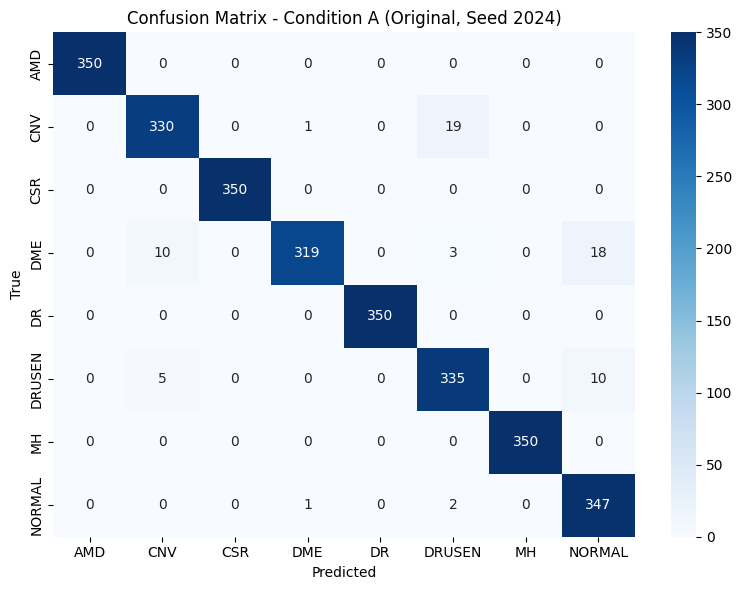

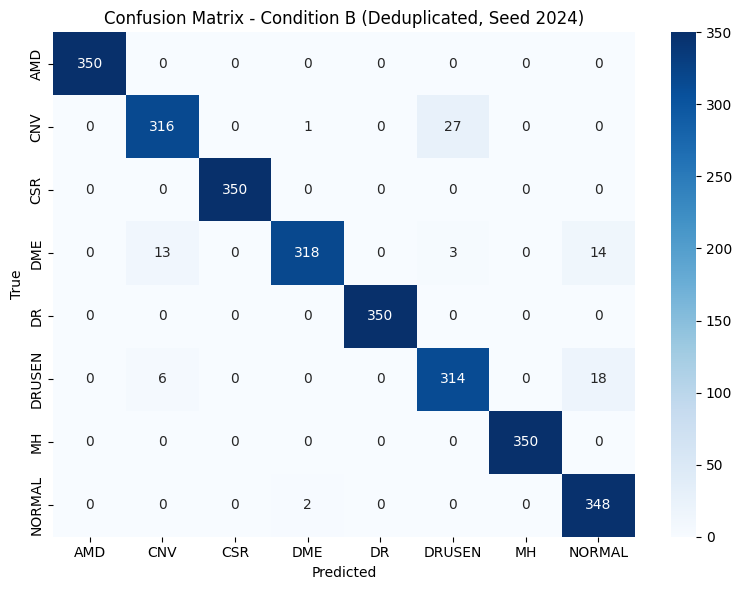

In [ ]:
os.makedirs(f'{PROJECT_DIR}/outputs/paper_figures', exist_ok=True)
FIG_DIR = f'{PROJECT_DIR}/outputs/paper_figures'

def plot_confusion(preds, labels, title, filename):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{filename}', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

plot_confusion(preds_A, labels_A, 'Confusion Matrix - Condition A (Original, Seed 2024)', 'confusion_matrix_A.png')
plot_confusion(preds_B, labels_B, 'Confusion Matrix - Condition B (Deduplicated, Seed 2024)', 'confusion_matrix_B.png')

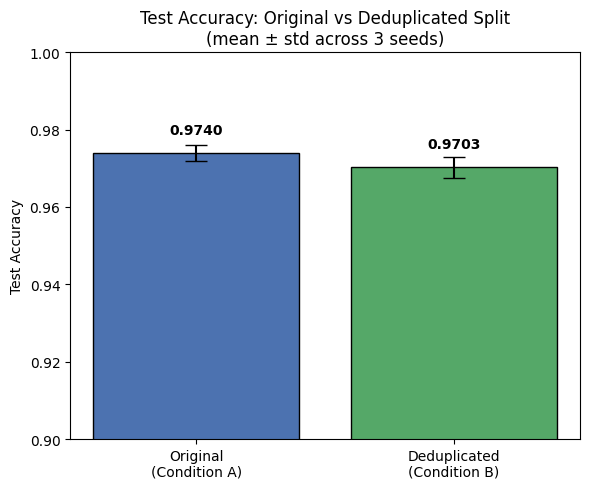

In [ ]:
plt.figure(figsize=(6, 5))
means = [np.mean(acc_A), np.mean(acc_B)]
stds = [np.std(acc_A), np.std(acc_B)]

bars = plt.bar(['Original\n(Condition A)', 'Deduplicated\n(Condition B)'], means, yerr=stds, capsize=8,
               color=['#4C72B0', '#55A868'], edgecolor='black')
plt.ylabel('Test Accuracy')
plt.title('Test Accuracy: Original vs Deduplicated Split\n(mean ± std across 3 seeds)')
plt.ylim(0.90, 1.0)
for bar, mean in zip(bars, means):
    plt.text(bar.get_x() + bar.get_width()/2, mean + 0.005, f'{mean:.4f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/accuracy_comparison_bar.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

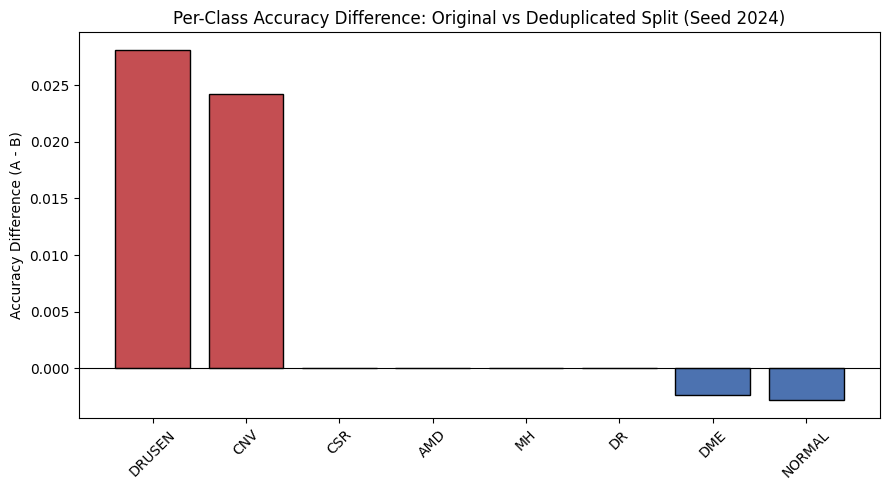

In [ ]:
plt.figure(figsize=(9, 5))
classes_sorted = per_class_df['class'].tolist()
diffs = per_class_df['diff (A - B)'].values

colors = ['#C44E52' if d > 0 else '#4C72B0' for d in diffs]
plt.bar(classes_sorted, diffs, color=colors, edgecolor='black')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Accuracy Difference (A - B)')
plt.title('Per-Class Accuracy Difference: Original vs Deduplicated Split (Seed 2024)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/per_class_accuracy_diff.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

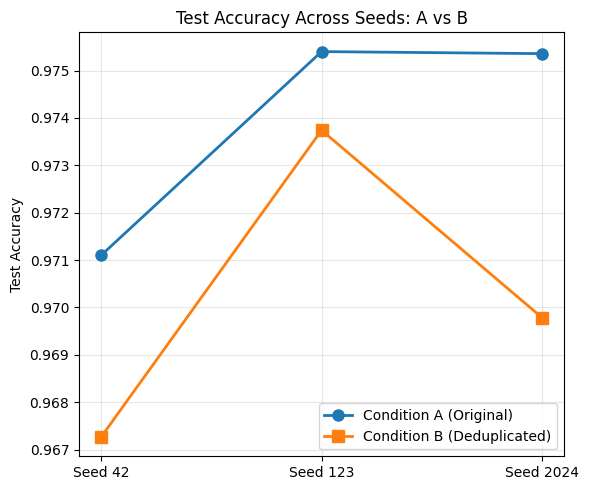

In [ ]:
plt.figure(figsize=(6, 5))
x = ['Seed 42', 'Seed 123', 'Seed 2024']
plt.plot(x, acc_A, marker='o', label='Condition A (Original)', linewidth=2, markersize=8)
plt.plot(x, acc_B, marker='s', label='Condition B (Deduplicated)', linewidth=2, markersize=8)
plt.ylabel('Test Accuracy')
plt.title('Test Accuracy Across Seeds: A vs B')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/accuracy_across_seeds.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

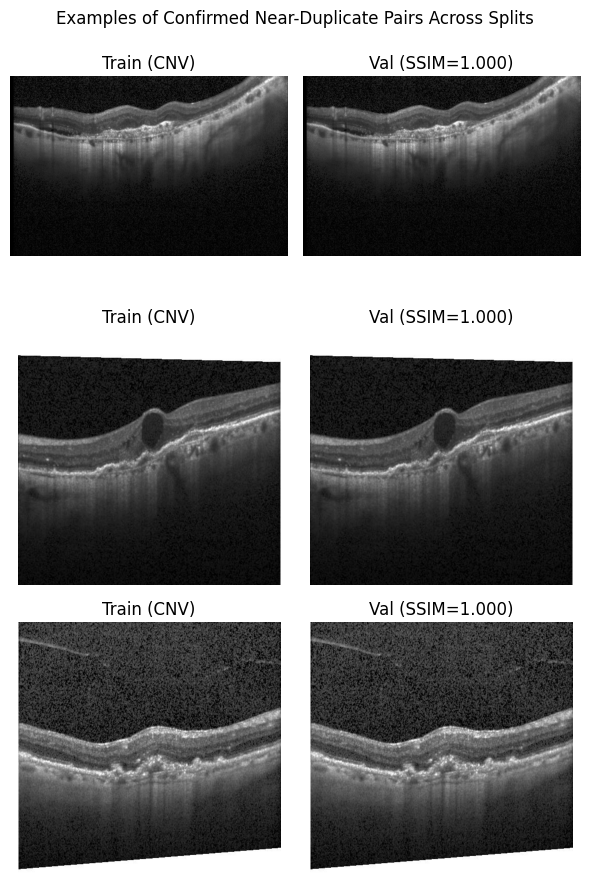

In [ ]:
tv_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv')
confirmed_pairs = tv_df[tv_df['confirmed_duplicate'] == True].head(3)

fig, axes = plt.subplots(len(confirmed_pairs), 2, figsize=(6, 3*len(confirmed_pairs)))
for i, (_, row) in enumerate(confirmed_pairs.iterrows()):
    img_train = plt.imread(row['train_path'])
    img_val = plt.imread(row['val_path'])
    axes[i, 0].imshow(img_train, cmap='gray')
    axes[i, 0].set_title(f"Train ({row['class']})")
    axes[i, 0].axis('off')
    axes[i, 1].imshow(img_val, cmap='gray')
    axes[i, 1].set_title(f"Val (SSIM={row['ssim_score']:.3f})")
    axes[i, 1].axis('off')

plt.suptitle('Examples of Confirmed Near-Duplicate Pairs Across Splits')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/duplicate_examples.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

class
DRUSEN    25
CNV       12
DME       11
NORMAL     1
Name: count, dtype: int64


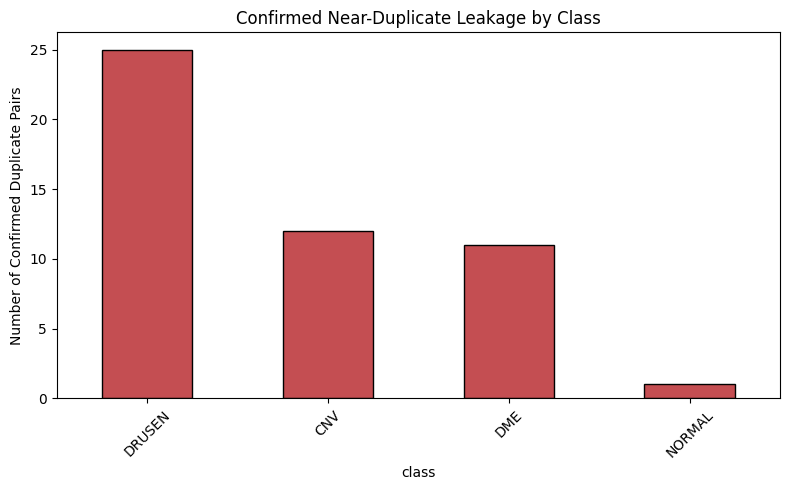

In [ ]:
tv_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv')
tt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')

tv_conf = tv_df[tv_df['confirmed_duplicate']]
tt_conf = tt_df[tt_df['confirmed_duplicate']]
vt_conf = vt_df[vt_df['confirmed_duplicate']]

# 'class' column thakle tv/tt/vt csv-e, na thakle path theke extract korte hobe
leak_counts = pd.concat([
    tv_conf['class'] if 'class' in tv_conf.columns else tv_conf['train_class'],
    tt_conf['class'] if 'class' in tt_conf.columns else tt_conf['train_class'],
    vt_conf['class'] if 'class' in vt_conf.columns else vt_conf['val_class'],
]).value_counts()

print(leak_counts)

plt.figure(figsize=(8,5))
leak_counts.plot(kind='bar', color='#C44E52', edgecolor='black')
plt.ylabel('Number of Confirmed Duplicate Pairs')
plt.title('Confirmed Near-Duplicate Leakage by Class')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/leak_count_by_class.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

In [ ]:
# CNV chara alada class theke example nichi, jate figure diverse hoy
diverse_examples = pd.concat([
    tv_conf[tv_conf.get('class', tv_conf.get('train_class')) != 'CNV'].head(2),
    tv_conf[tv_conf.get('class', tv_conf.get('train_class')) == 'CNV'].head(1),
])

In [ ]:
tt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')

tt_conf = tt_df[tt_df['confirmed_duplicate']]
vt_conf = vt_df[vt_df['confirmed_duplicate']]

print("Train-Test confirmed columns:", tt_conf.columns.tolist())
print(tt_conf.head())

Train-Test confirmed columns: ['train_path', 'test_path', 'class', 'hamming_distance', 'ssim_score', 'confirmed_duplicate']
                                           train_path  \
20  /content/drive/MyDrive/OCT_C8_Project/dataset/...   
21  /content/drive/MyDrive/OCT_C8_Project/dataset/...   
22  /content/drive/MyDrive/OCT_C8_Project/dataset/...   
33  /content/drive/MyDrive/OCT_C8_Project/dataset/...   
34  /content/drive/MyDrive/OCT_C8_Project/dataset/...   

                                            test_path class  hamming_distance  \
20  /content/drive/MyDrive/OCT_C8_Project/dataset/...   CNV                 0   
21  /content/drive/MyDrive/OCT_C8_Project/dataset/...   CNV                 0   
22  /content/drive/MyDrive/OCT_C8_Project/dataset/...   CNV                 0   
33  /content/drive/MyDrive/OCT_C8_Project/dataset/...   CNV                 0   
34  /content/drive/MyDrive/OCT_C8_Project/dataset/...   CNV                 0   

    ssim_score  confirmed_duplicate  
20      


Leaks affecting TEST set specifically:
class
DRUSEN    12
CNV        6
DME        2
Name: count, dtype: int64


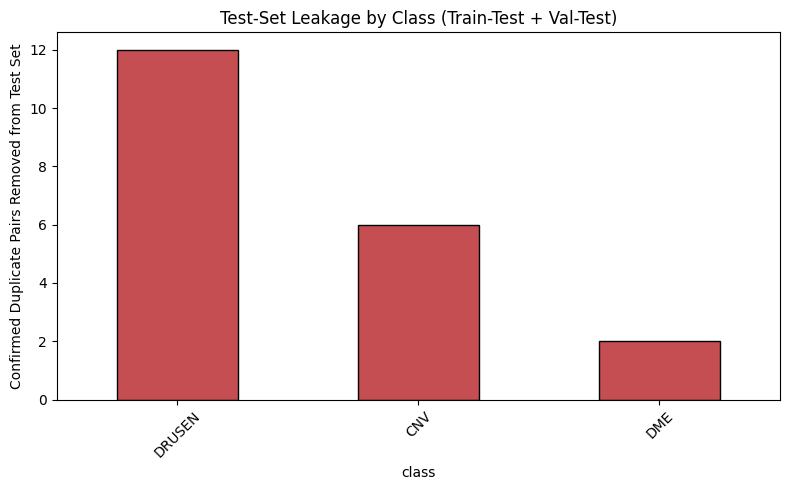

In [ ]:
# Column name confirm howar por eta run koro (dhoro column 'class' ache)
test_affecting_leaks = pd.concat([
    tt_conf['class'] if 'class' in tt_conf.columns else tt_conf['test_class'],
    vt_conf['class'] if 'class' in vt_conf.columns else vt_conf['test_class'],
])

test_leak_counts = test_affecting_leaks.value_counts()
print("\nLeaks affecting TEST set specifically:")
print(test_leak_counts)

plt.figure(figsize=(8,5))
test_leak_counts.plot(kind='bar', color='#C44E52', edgecolor='black')
plt.ylabel('Confirmed Duplicate Pairs Removed from Test Set')
plt.title('Test-Set Leakage by Class (Train-Test + Val-Test)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/test_leak_count_by_class.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

print("Ready:", PROJECT_DIR)
print(os.listdir(dataset_root))  # ['test', 'train', 'val'] asha uchit

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ready: /content/drive/MyDrive/OCT_C8_Project
['test', 'train', 'val']


In [ ]:
!pip install -q imagehash

import imagehash
from PIL import Image
import pandas as pd
import numpy as np

def popcount64(x):
    x = x - ((x >> np.uint64(1)) & np.uint64(0x5555555555555555))
    x = (x & np.uint64(0x3333333333333333)) + ((x >> np.uint64(2)) & np.uint64(0x3333333333333333))
    x = (x + (x >> np.uint64(4))) & np.uint64(0x0f0f0f0f0f0f0f0f)
    return (x * np.uint64(0x0101010101010101)) >> np.uint64(56)

def compute_hashes_by_class(split_path):
    data = {}
    for class_name in sorted(os.listdir(split_path)):
        class_dir = os.path.join(split_path, class_name)
        paths, hashes = [], []
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            try:
                h = imagehash.phash(Image.open(fpath))
                paths.append(fpath)
                hashes.append(int(str(h), 16))
            except Exception as e:
                print("Skip:", fpath, e)
        data[class_name] = (paths, np.array(hashes, dtype=np.uint64))
        print(f"  {class_name}: {len(paths)} hashed")
    return data

print("Hashing TRAIN...")
train_data = compute_hashes_by_class(os.path.join(dataset_root, 'train'))
print("Hashing VAL...")
val_data = compute_hashes_by_class(os.path.join(dataset_root, 'val'))
print("Hashing TEST...")
test_data = compute_hashes_by_class(os.path.join(dataset_root, 'test'))
print("All hashing done.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 10.9 MB/s eta 0:00:00
Hashing TRAIN...
  AMD: 2300 hashed
  CNV: 2300 hashed
  CSR: 2300 hashed
  DME: 2300 hashed
  DR: 2300 hashed
  DRUSEN: 2300 hashed
  MH: 2300 hashed
  NORMAL: 2300 hashed
Hashing VAL...
  AMD: 350 hashed
  CNV: 350 hashed
  CSR: 350 hashed
  DME: 350 hashed
  DR: 350 hashed
  DRUSEN: 350 hashed
  MH: 350 hashed
  NORMAL: 350 hashed
Hashing TEST...
  AMD: 350 hashed
  CNV: 350 hashed
  CSR: 350 hashed
  DME: 350 hashed
  DR: 350 hashed
  DRUSEN: 350 hashed
  MH: 350 hashed
  NORMAL: 350 hashed
All hashing done.


In [ ]:
import pandas as pd
import numpy as np

def count_leaks_at_threshold(data_a, data_b, threshold):
    """Total leak pair count across shared classes, ekta threshold-e"""
    total = 0
    classes = sorted(set(data_a.keys()) & set(data_b.keys()))
    for cls in classes:
        paths_a, hashes_a = data_a[cls]
        paths_b, hashes_b = data_b[cls]
        if len(hashes_a) == 0 or len(hashes_b) == 0:
            continue
        xor_matrix = hashes_a[:, None] ^ hashes_b[None, :]
        dist_matrix = popcount64(xor_matrix)
        total += int((dist_matrix <= threshold).sum())
    return total

THRESHOLDS = [0, 2, 4, 5, 6, 8, 10, 12]

sweep_results = []
for th in THRESHOLDS:
    tv = count_leaks_at_threshold(train_data, val_data, th)
    tt = count_leaks_at_threshold(train_data, test_data, th)
    vt = count_leaks_at_threshold(val_data, test_data, th)
    sweep_results.append({'threshold': th, 'train_val': tv, 'train_test': tt, 'val_test': vt, 'total': tv+tt+vt})
    print(f"Threshold={th}: Train-Val={tv}, Train-Test={tt}, Val-Test={vt}, Total={tv+tt+vt}")

sweep_df = pd.DataFrame(sweep_results)
sweep_df.to_csv(f'{PROJECT_DIR}/outputs/phash_threshold_sensitivity.csv', index=False)
print("\nSaved sensitivity table.")

Threshold=0: Train-Val=29, Train-Test=24, Val-Test=1, Total=54
Threshold=2: Train-Val=56, Train-Test=56, Val-Test=1, Total=113
Threshold=4: Train-Val=175, Train-Test=158, Val-Test=12, Total=345
Threshold=5: Train-Val=175, Train-Test=158, Val-Test=12, Total=345
Threshold=6: Train-Val=478, Train-Test=491, Val-Test=58, Total=1027
Threshold=8: Train-Val=1540, Train-Test=1550, Val-Test=230, Total=3320
Threshold=10: Train-Val=4822, Train-Test=4867, Val-Test=721, Total=10410
Threshold=12: Train-Val=13705, Train-Test=14212, Val-Test=2109, Total=30026

Saved sensitivity table.


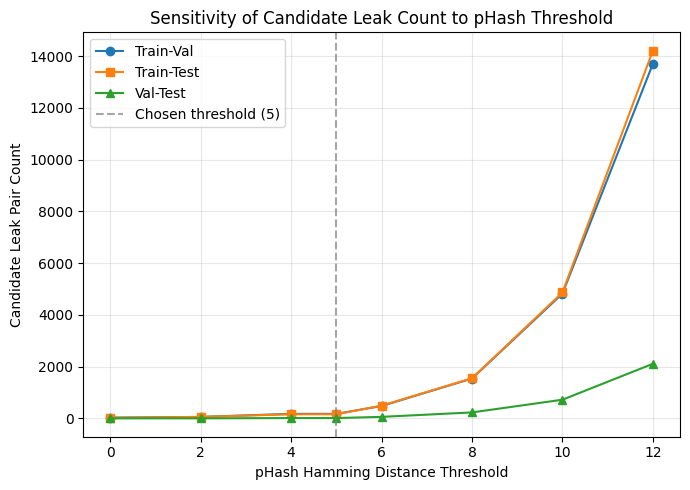

In [ ]:
import matplotlib.pyplot as plt

os.makedirs(f'{PROJECT_DIR}/outputs/paper_figures', exist_ok=True)
FIG_DIR = f'{PROJECT_DIR}/outputs/paper_figures'

plt.figure(figsize=(7,5))
plt.plot(sweep_df['threshold'], sweep_df['train_val'], marker='o', label='Train-Val')
plt.plot(sweep_df['threshold'], sweep_df['train_test'], marker='s', label='Train-Test')
plt.plot(sweep_df['threshold'], sweep_df['val_test'], marker='^', label='Val-Test')
plt.axvline(5, color='gray', linestyle='--', alpha=0.7, label='Chosen threshold (5)')
plt.xlabel('pHash Hamming Distance Threshold')
plt.ylabel('Candidate Leak Pair Count')
plt.title('Sensitivity of Candidate Leak Count to pHash Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/phash_threshold_sensitivity.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

SSIM>=0.8: Train-Val=30, Train-Test=23, Val-Test=2, Total=55
SSIM>=0.85: Train-Val=29, Train-Test=21, Val-Test=1, Total=51
SSIM>=0.9: Train-Val=29, Train-Test=19, Val-Test=1, Total=49
SSIM>=0.95: Train-Val=27, Train-Test=19, Val-Test=1, Total=47
SSIM>=0.99: Train-Val=26, Train-Test=19, Val-Test=1, Total=46


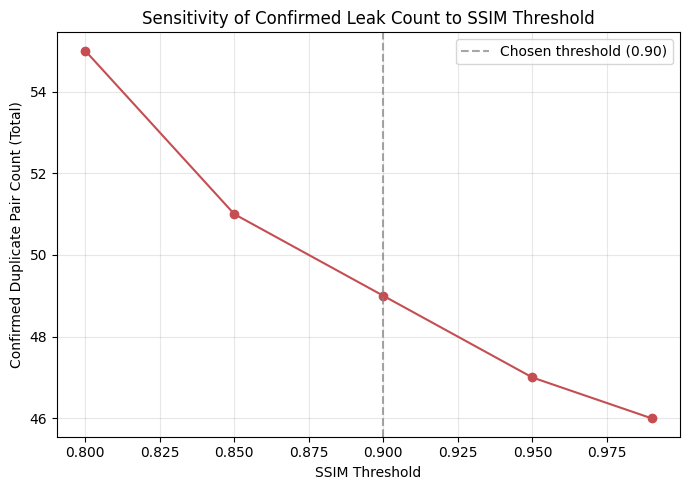

In [ ]:
tv_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv')
tt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')

SSIM_THRESHOLDS = [0.80, 0.85, 0.90, 0.95, 0.99]

ssim_sweep = []
for th in SSIM_THRESHOLDS:
    tv_c = (tv_df['ssim_score'] >= th).sum()
    tt_c = (tt_df['ssim_score'] >= th).sum()
    vt_c = (vt_df['ssim_score'] >= th).sum()
    ssim_sweep.append({'ssim_threshold': th, 'train_val': tv_c, 'train_test': tt_c, 'val_test': vt_c, 'total': tv_c+tt_c+vt_c})
    print(f"SSIM>={th}: Train-Val={tv_c}, Train-Test={tt_c}, Val-Test={vt_c}, Total={tv_c+tt_c+vt_c}")

ssim_sweep_df = pd.DataFrame(ssim_sweep)
ssim_sweep_df.to_csv(f'{PROJECT_DIR}/outputs/ssim_threshold_sensitivity.csv', index=False)

plt.figure(figsize=(7,5))
plt.plot(ssim_sweep_df['ssim_threshold'], ssim_sweep_df['total'], marker='o', color='#C44E52')
plt.axvline(0.90, color='gray', linestyle='--', alpha=0.7, label='Chosen threshold (0.90)')
plt.xlabel('SSIM Threshold')
plt.ylabel('Confirmed Duplicate Pair Count (Total)')
plt.title('Sensitivity of Confirmed Leak Count to SSIM Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/ssim_threshold_sensitivity.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

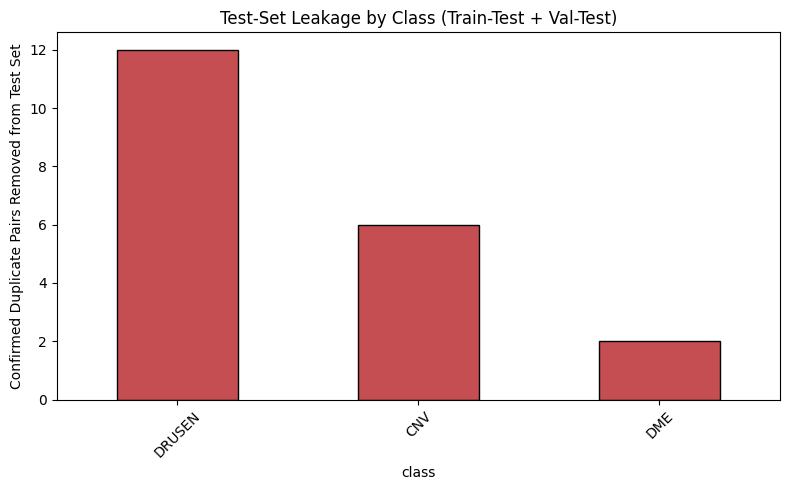

         metric    t_stat   p_value  mean_diff  std_diff  cohens_d
0  paired_ttest  3.257939  0.082695   0.003689  0.001601   2.30371


In [ ]:
# --- Test-set-specific leak chart, save kore rakhi ---
tt_conf = tt_df[tt_df['confirmed_duplicate']]
vt_conf = vt_df[vt_df['confirmed_duplicate']]

test_affecting_leaks = pd.concat([tt_conf['class'], vt_conf['class']])
test_leak_counts = test_affecting_leaks.value_counts()
test_leak_counts.to_csv(f'{PROJECT_DIR}/outputs/test_leak_counts_by_class.csv')

plt.figure(figsize=(8,5))
test_leak_counts.plot(kind='bar', color='#C44E52', edgecolor='black')
plt.ylabel('Confirmed Duplicate Pairs Removed from Test Set')
plt.title('Test-Set Leakage by Class (Train-Test + Val-Test)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/test_leak_count_by_class.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# --- Statistical test result, save kore rakhi ---
from scipy import stats
acc_A = [0.9711, 0.9754, 0.975357]
acc_B = [0.967266, 0.973741, 0.969784]
t_stat, p_value = stats.ttest_rel(acc_A, acc_B)
diff = np.array(acc_A) - np.array(acc_B)
cohens_d = diff.mean() / diff.std()

stat_summary = pd.DataFrame([{
    'metric': 'paired_ttest',
    't_stat': t_stat, 'p_value': p_value,
    'mean_diff': diff.mean(), 'std_diff': diff.std(), 'cohens_d': cohens_d
}])
stat_summary.to_csv(f'{PROJECT_DIR}/outputs/statistical_test_summary.csv', index=False)
print(stat_summary)

In [ ]:
from sklearn.metrics import classification_report

print("=== Condition A (seed 2024) ===")
print(classification_report(labels_A, preds_A, target_names=CLASS_NAMES, digits=4))

print("\n=== Condition B (seed 2024) ===")
print(classification_report(labels_B, preds_B, target_names=CLASS_NAMES, digits=4))

# Save as CSV too
report_A = classification_report(labels_A, preds_A, target_names=CLASS_NAMES, digits=4, output_dict=True)
report_B = classification_report(labels_B, preds_B, target_names=CLASS_NAMES, digits=4, output_dict=True)

pd.DataFrame(report_A).transpose().to_csv(f'{PROJECT_DIR}/outputs/classification_report_A.csv')
pd.DataFrame(report_B).transpose().to_csv(f'{PROJECT_DIR}/outputs/classification_report_B.csv')
print("\nSaved classification reports.")

=== Condition A (seed 2024) ===
              precision    recall  f1-score   support

         AMD     1.0000    1.0000    1.0000       350
         CNV     0.9565    0.9429    0.9496       350
         CSR     1.0000    1.0000    1.0000       350
         DME     0.9938    0.9114    0.9508       350
          DR     1.0000    1.0000    1.0000       350
      DRUSEN     0.9331    0.9571    0.9450       350
          MH     1.0000    1.0000    1.0000       350
      NORMAL     0.9253    0.9914    0.9572       350

    accuracy                         0.9754      2800
   macro avg     0.9761    0.9754    0.9753      2800
weighted avg     0.9761    0.9754    0.9753      2800


=== Condition B (seed 2024) ===
              precision    recall  f1-score   support

         AMD     1.0000    1.0000    1.0000       350
         CNV     0.9433    0.9186    0.9308       344
         CSR     1.0000    1.0000    1.0000       350
         DME     0.9907    0.9138    0.9507       348
          DR 

In [ ]:
import pandas as pd

tv_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_val_verified.csv')
tt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_train_test_verified.csv')
vt_df = pd.read_csv(f'{PROJECT_DIR}/outputs/leaks_val_test_verified.csv')

tv_conf = tv_df[tv_df['confirmed_duplicate']]
tt_conf = tt_df[tt_df['confirmed_duplicate']]
vt_conf = vt_df[vt_df['confirmed_duplicate']]

leak_counts = pd.concat([tv_conf['class'], tt_conf['class'], vt_conf['class']]).value_counts()

leak_counts_df = leak_counts.reset_index()
leak_counts_df.columns = ['class', 'confirmed_duplicate_pairs']
leak_counts_df.to_csv(f'{PROJECT_DIR}/outputs/all_leaks_by_class.csv', index=False)

print(leak_counts_df)
print("\nSaved to all_leaks_by_class.csv")

    class  confirmed_duplicate_pairs
0  DRUSEN                         25
1     CNV                         12
2     DME                         11
3  NORMAL                          1

Saved to all_leaks_by_class.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'
print(os.listdir(dataset_root))  # ['test', 'train', 'val'] asha uchit

Mounted at /content/drive
['test', 'train', 'val']


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time
import pickle
import pandas as pd
import glob

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if device.type != 'cuda':
    print("WARNING: GPU on na — Runtime > Change runtime type > GPU kore Cell 1 theke abar shuru koro")

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)
print("Train:", len(splits['condA_train']), "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780


In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_model(num_classes=8):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels)

def run_experiment(train_list, val_list, test_list, seed, epochs=10, batch_size=32, lr=1e-4):
    set_seed(seed)
    train_loader = DataLoader(OCTDataset(train_list, train_transform), batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(OCTDataset(val_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(OCTDataset(test_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_model(len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _ = evaluate(model, val_loader)
        print(f"    Epoch {epoch+1}/{epochs} | loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")

    test_acc, preds, labels = evaluate(model, test_loader)
    return test_acc, preds, labels

In [ ]:
SEEDS = [42, 123, 2024, 7, 17, 55, 99]   # original 3 + 4 notun (chao to ei list e add/remove korte paro)
EPOCHS = 10

def preds_path(letter, seed):
    return f'{PROJECT_DIR}/outputs/preds_{letter}_seed{seed}.pkl'

def results_path(condition):
    return f'{PROJECT_DIR}/outputs/{condition}_results.csv'

def upsert_result(condition, cond_label, seed, test_acc):
    p = results_path(condition)
    df = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame(columns=['condition', 'seed', 'test_acc'])
    df = df[df['seed'] != seed]  # purono thakle sorao (upsert)
    df = pd.concat([df, pd.DataFrame([{'condition': cond_label, 'seed': seed, 'test_acc': test_acc}])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    df.to_csv(p, index=False)
    return df

CONDITIONS = [('condA', 'A', 'A_original'), ('condB', 'B', 'B_deduplicated')]

for condition, letter, cond_label in CONDITIONS:
    train_l = splits[f'{condition}_train']
    val_l   = splits[f'{condition}_val']
    test_l  = splits[f'{condition}_test']
    print(f"\n{'='*60}\n{cond_label} — {len(SEEDS)}-ta seed check hocche\n{'='*60}")

    for seed in SEEDS:
        pfile = preds_path(letter, seed)
        if os.path.exists(pfile):
            print(f"[{cond_label} | seed {seed}] already saved — skip")
            continue

        print(f"[{cond_label} | seed {seed}] running...")
        start = time.time()
        test_acc, preds, labels = run_experiment(train_l, val_l, test_l, seed, epochs=EPOCHS)
        elapsed = (time.time() - start) / 60

        # --- IMMEDIATELY save, run shesh hoyei ---
        with open(pfile, 'wb') as f:
            pickle.dump((preds, labels), f)
        upsert_result(condition, cond_label, seed, test_acc)

        print(f"[{cond_label} | seed {seed}] DONE — test_acc={test_acc:.4f} | {elapsed:.1f} min | saved.")

print("\nSob shesh (ba ekhon porjonto jotota holo).")


A_original — 7-ta seed check hocche
[A_original | seed 42] running...
    Epoch 1/10 | loss=0.2596 train_acc=0.9106 val_acc=0.9504
    Epoch 2/10 | loss=0.1245 train_acc=0.9594 val_acc=0.9496
    Epoch 3/10 | loss=0.1041 train_acc=0.9668 val_acc=0.9668
    Epoch 4/10 | loss=0.0866 train_acc=0.9709 val_acc=0.9675
    Epoch 5/10 | loss=0.0801 train_acc=0.9732 val_acc=0.9686


In [ ]:
for cond in ['condA', 'condB']:
    p = f'{PROJECT_DIR}/outputs/{cond}_results.csv'
    if os.path.exists(p):
        df = pd.read_csv(p)
        print(f"{cond}: seeds done = {sorted(df['seed'].tolist())}")
    else:
        print(f"{cond}: kono result nei ekhono")

print("\nSaved prediction files:")
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/preds_*_seed*.pkl')):
    print(" ", os.path.basename(f))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'
print(os.listdir(dataset_root))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['test', 'train', 'val']


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time
import pickle
import pandas as pd
import glob

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if device.type != 'cuda':
    print("WARNING: GPU on na — Runtime > Change runtime type > GPU")

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)
print("Train:", len(splits['condA_train']), "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780


In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_model(num_classes=8):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels)

def run_experiment(train_list, val_list, test_list, seed, epochs=10, batch_size=32, lr=1e-4):
    set_seed(seed)
    train_loader = DataLoader(OCTDataset(train_list, train_transform), batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(OCTDataset(val_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(OCTDataset(test_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_model(len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _ = evaluate(model, val_loader)
        print(f"    Epoch {epoch+1}/{epochs} | loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")

    test_acc, preds, labels = evaluate(model, test_loader)
    return test_acc, preds, labels

In [ ]:
SEEDS = [42, 123, 2024, 7, 17, 55, 99]
EPOCHS = 10

def preds_path(letter, seed):
    return f'{PROJECT_DIR}/outputs/preds_{letter}_seed{seed}.pkl'

def results_path(condition):
    return f'{PROJECT_DIR}/outputs/{condition}_results.csv'

def upsert_result(condition, cond_label, seed, test_acc):
    p = results_path(condition)
    df = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame(columns=['condition', 'seed', 'test_acc'])
    df = df[df['seed'] != seed]
    df = pd.concat([df, pd.DataFrame([{'condition': cond_label, 'seed': seed, 'test_acc': test_acc}])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    df.to_csv(p, index=False)
    return df

CONDITIONS = [('condA', 'A', 'A_original'), ('condB', 'B', 'B_deduplicated')]

for condition, letter, cond_label in CONDITIONS:
    train_l = splits[f'{condition}_train']
    val_l   = splits[f'{condition}_val']
    test_l  = splits[f'{condition}_test']
    print(f"\n{'='*60}\n{cond_label} — {len(SEEDS)}-ta seed check hocche\n{'='*60}")

    for seed in SEEDS:
        pfile = preds_path(letter, seed)
        if os.path.exists(pfile):
            print(f"[{cond_label} | seed {seed}] already saved — skip")
            continue

        print(f"[{cond_label} | seed {seed}] running...")
        start = time.time()
        test_acc, preds, labels = run_experiment(train_l, val_l, test_l, seed, epochs=EPOCHS)
        elapsed = (time.time() - start) / 60

        with open(pfile, 'wb') as f:
            pickle.dump((preds, labels), f)
        upsert_result(condition, cond_label, seed, test_acc)

        print(f"[{cond_label} | seed {seed}] DONE — test_acc={test_acc:.4f} | {elapsed:.1f} min | saved.")

print("\nSob shesh (ba ekhon porjonto jotota holo).")


A_original — 7-ta seed check hocche
[A_original | seed 42] running...


KeyboardInterrupt: 

In [ ]:
for cond in ['condA', 'condB']:
    p = f'{PROJECT_DIR}/outputs/{cond}_results.csv'
    if os.path.exists(p):
        df = pd.read_csv(p)
        print(f"{cond}: seeds done = {sorted(df['seed'].tolist())}")
    else:
        print(f"{cond}: kono result nei ekhono")

print("\nSaved prediction files:")
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/preds_*_seed*.pkl')):
    print(" ", os.path.basename(f))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
dataset_root = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'
print(os.listdir(dataset_root))  # expect ['test', 'train', 'val']

Mounted at /content/drive
['test', 'train', 'val']


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time
import pickle
import pandas as pd
import glob

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if device.type != 'cuda':
    print("WARNING: GPU not on — Runtime > Change runtime type > GPU, then redo from Cell 1")

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)
print("Train:", len(splits['condA_train']), "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780


In [ ]:
import torch.nn.functional as Fnn

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def build_model(num_classes=8):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward(); optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate_full(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = Fnn.softmax(outputs, dim=1)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels), np.array(all_probs)

def checkpoint_path(letter, seed):
    os.makedirs(f'{PROJECT_DIR}/outputs/checkpoints', exist_ok=True)
    return f'{PROJECT_DIR}/outputs/checkpoints/ckpt_{letter}_seed{seed}.pt'

def run_experiment_resumable(train_list, val_list, test_list, seed, letter, epochs=10, batch_size=32, lr=1e-4):
    set_seed(seed)
    train_loader = DataLoader(OCTDataset(train_list, train_transform), batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(OCTDataset(val_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(OCTDataset(test_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_model(len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    ckpt_path = checkpoint_path(letter, seed)
    start_epoch = 0
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        start_epoch = ckpt['epoch'] + 1
        print(f"    >> Resuming from epoch {start_epoch+1} (checkpoint found)")

    for epoch in range(start_epoch, epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _, _ = evaluate_full(model, val_loader)
        print(f"    Epoch {epoch+1}/{epochs} | loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")
        torch.save({'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict()}, ckpt_path)

    test_acc, preds, labels, probs = evaluate_full(model, test_loader)
    return test_acc, preds, labels, probs, model

In [ ]:
SEEDS = [42, 123, 2024, 7, 17, 55, 99]
EPOCHS = 10
KEEP_CHECKPOINT_FOR = [('A', 2024)]

def full_results_path(letter, seed):
    return f'{PROJECT_DIR}/outputs/full_results_{letter}_seed{seed}.pkl'

def results_path(condition):
    return f'{PROJECT_DIR}/outputs/{condition}_results.csv'

def upsert_result(condition, cond_label, seed, test_acc):
    p = results_path(condition)
    df = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame(columns=['condition', 'seed', 'test_acc'])
    df = df[df['seed'] != seed]
    df = pd.concat([df, pd.DataFrame([{'condition': cond_label, 'seed': seed, 'test_acc': test_acc}])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    df.to_csv(p, index=False)
    return df

CONDITIONS = [('condA', 'A', 'A_original'), ('condB', 'B', 'B_deduplicated')]

for condition, letter, cond_label in CONDITIONS:
    train_l = splits[f'{condition}_train']
    val_l   = splits[f'{condition}_val']
    test_l  = splits[f'{condition}_test']
    print(f"\n{'='*60}\n{cond_label} — checking {len(SEEDS)} seeds\n{'='*60}")

    for seed in SEEDS:
        rfile = full_results_path(letter, seed)
        if os.path.exists(rfile):
            print(f"[{cond_label} | seed {seed}] already fully done — skip")
            continue
        print(f"[{cond_label} | seed {seed}] running (resumable, checkpointed every epoch)...")
        start = time.time()
        test_acc, preds, labels, probs, model = run_experiment_resumable(train_l, val_l, test_l, seed, letter, epochs=EPOCHS)
        elapsed = (time.time() - start) / 60
        with open(rfile, 'wb') as f:
            pickle.dump({'preds': preds, 'labels': labels, 'probs': probs}, f)
        upsert_result(condition, cond_label, seed, test_acc)
        ckpt = checkpoint_path(letter, seed)
        if (letter, seed) in KEEP_CHECKPOINT_FOR:
            print(f"    (keeping checkpoint for {letter}/{seed} — reserved for Priority 2A)")
        elif os.path.exists(ckpt):
            os.remove(ckpt)
        print(f"[{cond_label} | seed {seed}] DONE — test_acc={test_acc:.4f} | {elapsed:.1f} min | saved.")

print("\nAll done (or as far as this session got).")


A_original — checking 7 seeds
[A_original | seed 42] running (resumable, checkpointed every epoch)...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 138MB/s]


KeyboardInterrupt: 

In [ ]:
# Cell 1 — Mount Google Drive so we can read the dataset and save all outputs/checkpoints there
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
DRIVE_DATASET_ROOT = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

print(os.listdir(DRIVE_DATASET_ROOT))  # expect ['test', 'train', 'val']

Mounted at /content/drive
['test', 'train', 'val']


In [ ]:
# Cell 1B — Copy the dataset from Drive to local Colab disk once per session.
# Reason: reading thousands of small image files directly from a mounted/shared
# Drive folder during training is extremely slow and can hang with no error.
# Training will read from local disk instead; all results still get saved back to Drive.

import os, shutil, time

LOCAL_DATASET_ROOT = '/content/dataset_local/RetinalOCT_Dataset'
SENTINEL = f'{LOCAL_DATASET_ROOT}/.copy_complete'  # marker file so we don't re-copy if this cell reruns

if not os.path.exists(SENTINEL):
    if os.path.exists(LOCAL_DATASET_ROOT):
        shutil.rmtree(LOCAL_DATASET_ROOT)  # remove any incomplete previous copy
    print("Copying dataset from Drive to local disk (one-time this session, ~1.4GB)...")
    start = time.time()
    shutil.copytree(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
    with open(SENTINEL, 'w') as f:
        f.write('done')
    print(f"Copy finished in {(time.time() - start) / 60:.1f} min.")
else:
    print("Local dataset copy already complete this session — skipping.")

print(os.listdir(LOCAL_DATASET_ROOT))  # expect ['test', 'train', 'val']

Copying dataset from Drive to local disk (one-time this session, ~1.4GB)...
Copy finished in 11.3 min.
['.copy_complete', 'test', 'train', 'val']


In [ ]:
# Cell 2 — Core imports, custom PyTorch Dataset class, and image preprocessing/augmentation pipelines
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time
import pickle
import pandas as pd
import glob

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if device.type != 'cuda':
    print("WARNING: GPU not on — go to Runtime > Change runtime type > GPU, then redo from Cell 1")

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    # Wraps a list of (filepath, class_name) tuples into a PyTorch-compatible dataset
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')  # OCT scans are greyscale but stored/read as RGB for ResNet
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

# Training transform: light augmentation (rotation + horizontal flip) as used in the paper
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # ImageNet stats, matches pretrained backbone
])

# Validation/test transform: no augmentation, only resize + normalize
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
# Cell 3 — Load the pre-computed train/val/test file lists (Condition A = original, Condition B = deduplicated)
# and rewrite every file path from the Drive location to the local-disk copy made in Cell 1B.

with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)

def remap_paths_to_local(file_label_list):
    # Replaces the Drive dataset root with the local dataset root in every file path
    return [(fpath.replace(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT), class_name) for fpath, class_name in file_label_list]

for key in list(splits.keys()):
    splits[key] = remap_paths_to_local(splits[key])

# Sanity check: confirm the remapped path actually exists on local disk
sample_path = splits['condA_train'][0][0]
print("Sample remapped path:", sample_path)
print("Exists on local disk:", os.path.exists(sample_path))

print("Train:", len(splits['condA_train']),
      "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

Sample remapped path: /content/dataset_local/RetinalOCT_Dataset/train/AMD/amd_train_2301.jpg
Exists on local disk: True
Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780


In [ ]:
# Cell 4B — Defines: seeding, model builder, one training epoch, full evaluation (accuracy + predictions
# + labels + softmax probabilities for later ROC-AUC), per-epoch checkpoint save/resume logic, and the
# full resumable single-run trainer used for every (condition, seed) combination.

import torch.nn.functional as Fnn

def set_seed(seed):
    # Fixes all relevant random seeds so a given seed run is reproducible
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_model(num_classes=8):
    # ResNet18 with ImageNet-pretrained weights, final layer replaced for 8-class OCT classification
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    # Runs one full pass over the training set; returns average loss and training accuracy
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate_full(model, loader):
    # Runs inference over a loader; returns accuracy, hard predictions, true labels, and softmax
    # probabilities (probabilities are required later for ROC-AUC, which the old pipeline never saved)
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = Fnn.softmax(outputs, dim=1)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels), np.array(all_probs)

def checkpoint_path(letter, seed):
    # Path (on Drive) where this (condition, seed)'s in-progress model checkpoint is stored
    os.makedirs(f'{PROJECT_DIR}/outputs/checkpoints', exist_ok=True)
    return f'{PROJECT_DIR}/outputs/checkpoints/ckpt_{letter}_seed{seed}.pt'

def run_experiment_resumable(train_list, val_list, test_list, seed, letter, epochs=10, batch_size=32, lr=1e-4):
    # Trains one (condition, seed) combination end to end.
    # If a checkpoint already exists for this (letter, seed), resumes from the next epoch
    # instead of restarting — so a session crash never loses more than one epoch of progress.
    set_seed(seed)
    train_loader = DataLoader(OCTDataset(train_list, train_transform), batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(OCTDataset(val_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(OCTDataset(test_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_model(len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    ckpt_path = checkpoint_path(letter, seed)
    start_epoch = 0
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        start_epoch = ckpt['epoch'] + 1
        print(f"    >> Resuming from epoch {start_epoch + 1} (checkpoint found)")

    for epoch in range(start_epoch, epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _, _ = evaluate_full(model, val_loader)
        print(f"    Epoch {epoch + 1}/{epochs} | loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")

        # Save checkpoint after EVERY epoch — a crash now loses at most 1 epoch, not the whole run
        torch.save({'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict()}, ckpt_path)

    test_acc, preds, labels, probs = evaluate_full(model, test_loader)
    return test_acc, preds, labels, probs, model

In [ ]:
# Cell 5B — The main driver loop. For each condition (A, B) and each seed, skips any combination
# that's already fully saved, otherwise trains it (resumable at the epoch level via Cell 4B) and
# immediately saves predictions + labels + probabilities + updates the running accuracy CSV.
# Safe to stop and re-run this cell any number of times, in any session, on any Google account.

SEEDS = [42, 123, 2024, 7, 17, 55, 99]
EPOCHS = 10
KEEP_CHECKPOINT_FOR = [('A', 2024)]  # keep this one checkpoint permanently for the later Priority-2A experiment

def full_results_path(letter, seed):
    return f'{PROJECT_DIR}/outputs/full_results_{letter}_seed{seed}.pkl'

def results_path(condition):
    return f'{PROJECT_DIR}/outputs/{condition}_results.csv'

def upsert_result(condition, cond_label, seed, test_acc):
    # Adds/updates this seed's accuracy in the condition's running CSV log (immediate save, not batched)
    p = results_path(condition)
    df = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame(columns=['condition', 'seed', 'test_acc'])
    df = df[df['seed'] != seed]
    df = pd.concat([df, pd.DataFrame([{'condition': cond_label, 'seed': seed, 'test_acc': test_acc}])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    df.to_csv(p, index=False)
    return df

CONDITIONS = [('condA', 'A', 'A_original'), ('condB', 'B', 'B_deduplicated')]

for condition, letter, cond_label in CONDITIONS:
    train_l = splits[f'{condition}_train']
    val_l   = splits[f'{condition}_val']
    test_l  = splits[f'{condition}_test']
    print(f"\n{'=' * 60}\n{cond_label} — checking {len(SEEDS)} seeds\n{'=' * 60}")

    for seed in SEEDS:
        rfile = full_results_path(letter, seed)
        if os.path.exists(rfile):
            print(f"[{cond_label} | seed {seed}] already fully done — skip")
            continue

        print(f"[{cond_label} | seed {seed}] running (resumable, checkpointed every epoch)...")
        start = time.time()
        test_acc, preds, labels, probs, model = run_experiment_resumable(train_l, val_l, test_l, seed, letter, epochs=EPOCHS)
        elapsed = (time.time() - start) / 60

        # Save full results (predictions + labels + probabilities) immediately — do not wait until all seeds finish
        with open(rfile, 'wb') as f:
            pickle.dump({'preds': preds, 'labels': labels, 'probs': probs}, f)
        upsert_result(condition, cond_label, seed, test_acc)

        # Delete the checkpoint now that the run is fully saved (unless it's the one reserved for Priority 2A)
        ckpt = checkpoint_path(letter, seed)
        if (letter, seed) in KEEP_CHECKPOINT_FOR:
            print(f"    (keeping checkpoint for {letter}/{seed} — reserved for Priority 2A)")
        elif os.path.exists(ckpt):
            os.remove(ckpt)

        print(f"[{cond_label} | seed {seed}] DONE — test_acc={test_acc:.4f} | {elapsed:.1f} min | saved.")

print("\nAll done (or as far as this session got).")


A_original — checking 7 seeds
[A_original | seed 42] already fully done — skip
[A_original | seed 123] already fully done — skip
[A_original | seed 2024] already fully done — skip
[A_original | seed 7] already fully done — skip
[A_original | seed 17] already fully done — skip
[A_original | seed 55] running (resumable, checkpointed every epoch)...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 123MB/s]


    >> Resuming from epoch 4 (checkpoint found)
    Epoch 4/10 | loss=0.0744 train_acc=0.9757 val_acc=0.9682
    Epoch 5/10 | loss=0.0559 train_acc=0.9816 val_acc=0.9668
    Epoch 6/10 | loss=0.0524 train_acc=0.9830 val_acc=0.9611
    Epoch 7/10 | loss=0.0767 train_acc=0.9731 val_acc=0.9668
    Epoch 8/10 | loss=0.0652 train_acc=0.9780 val_acc=0.9675
    Epoch 9/10 | loss=0.0597 train_acc=0.9810 val_acc=0.9643
    Epoch 10/10 | loss=0.0499 train_acc=0.9834 val_acc=0.9682
[A_original | seed 55] DONE — test_acc=0.9746 | 16.5 min | saved.
[A_original | seed 99] running (resumable, checkpointed every epoch)...
    Epoch 1/10 | loss=0.2613 train_acc=0.9122 val_acc=0.9614
    Epoch 2/10 | loss=0.1238 train_acc=0.9585 val_acc=0.9596
    Epoch 3/10 | loss=0.1041 train_acc=0.9650 val_acc=0.9586
    Epoch 4/10 | loss=0.0892 train_acc=0.9698 val_acc=0.9675
    Epoch 5/10 | loss=0.0829 train_acc=0.9718 val_acc=0.9700
    Epoch 6/10 | loss=0.0738 train_acc=0.9752 val_acc=0.9596
    Epoch 7/10 | los

In [ ]:
# Cell 6B — Reports exactly what's done, what's mid-run (and which epoch it'll resume from),
# and what old-style (pre-upgrade) files still exist. Run this any time to check status.

for cond in ['condA', 'condB']:
    p = f'{PROJECT_DIR}/outputs/{cond}_results.csv'
    if os.path.exists(p):
        df = pd.read_csv(p)
        print(f"{cond}: seeds with final accuracy recorded = {sorted(df['seed'].tolist())}")
    else:
        print(f"{cond}: no results yet")

print("\nFully-finished runs (full_results_*.pkl, includes probabilities):")
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/full_results_*_seed*.pkl')):
    print(" ", os.path.basename(f))

print("\nIn-progress checkpoints (partial runs, will auto-resume from here):")
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/checkpoints/ckpt_*_seed*.pt')):
    ckpt = torch.load(f, map_location='cpu')
    print(f"  {os.path.basename(f)} — completed up through epoch {ckpt['epoch'] + 1}")

print("\nOLD-style files (pre-upgrade, preds+labels only, NO probabilities/ROC-AUC possible):")
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/preds_*_seed*.pkl')):
    print(" ", os.path.basename(f))

condA: seeds with final accuracy recorded = [7, 17, 42, 55, 99, 123, 2024]
condB: seeds with final accuracy recorded = [7, 17, 42, 55, 99, 123, 2024]

Fully-finished runs (full_results_*.pkl, includes probabilities):
  full_results_A_seed123.pkl
  full_results_A_seed17.pkl
  full_results_A_seed2024.pkl
  full_results_A_seed42.pkl
  full_results_A_seed55.pkl
  full_results_A_seed7.pkl
  full_results_A_seed99.pkl
  full_results_B_seed123.pkl
  full_results_B_seed17.pkl
  full_results_B_seed2024.pkl
  full_results_B_seed42.pkl
  full_results_B_seed55.pkl
  full_results_B_seed7.pkl
  full_results_B_seed99.pkl

In-progress checkpoints (partial runs, will auto-resume from here):
  ckpt_A_seed2024.pt — completed up through epoch 10

OLD-style files (pre-upgrade, preds+labels only, NO probabilities/ROC-AUC possible):
  preds_A_seed2024.pkl
  preds_B_seed123.pkl
  preds_B_seed2024.pkl
  preds_B_seed42.pkl


In [ ]:
# Cell 7 — Computes Accuracy, Precision, Recall, F1, Specificity, ROC-AUC, and Confusion Matrix
# (macro-average + per-class) for every completed new-style run, and saves one master CSV.
# This becomes the authoritative results table for the paper.

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import numpy as np

def compute_full_metrics(preds, labels, probs=None, class_names=CLASS_NAMES):
    n = len(class_names)
    cm = confusion_matrix(labels, preds, labels=list(range(n)))
    report = classification_report(labels, preds, target_names=class_names, output_dict=True, digits=4)

    # Specificity isn't in sklearn's classification_report, so compute it manually per class
    specificity = {}
    total = cm.sum()
    for i, c in enumerate(class_names):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = total - TP - FN - FP
        specificity[c] = TN / (TN + FP) if (TN + FP) > 0 else float('nan')

    result = {
        'accuracy': report['accuracy'],
        'macro_precision': report['macro avg']['precision'],
        'macro_recall': report['macro avg']['recall'],
        'macro_f1': report['macro avg']['f1-score'],
        'macro_specificity': float(np.nanmean(list(specificity.values()))),
    }
    for c in class_names:
        result[f'{c}_precision'] = report[c]['precision']
        result[f'{c}_recall'] = report[c]['recall']
        result[f'{c}_f1'] = report[c]['f1-score']
        result[f'{c}_specificity'] = specificity[c]

    # ROC-AUC needs probability scores, only available from the new-style (Cell 4B/5B) runs
    if probs is not None:
        try:
            auc_macro = roc_auc_score(labels, probs, multi_class='ovr', average='macro', labels=list(range(n)))
            result['macro_roc_auc'] = auc_macro
            per_class_auc = roc_auc_score(labels, probs, multi_class='ovr', average=None, labels=list(range(n)))
            for i, c in enumerate(class_names):
                result[f'{c}_roc_auc'] = per_class_auc[i]
        except Exception as e:
            print("  (ROC-AUC skipped:", e, ")")

    return result, cm

# Model parameter count is architecture-only, independent of any specific run
_tmp_model = build_model(len(CLASS_NAMES))
n_params = sum(p.numel() for p in _tmp_model.parameters())
n_trainable = sum(p.numel() for p in _tmp_model.parameters() if p.requires_grad)
print(f"ResNet18 total parameters: {n_params:,} | trainable: {n_trainable:,}")
del _tmp_model

# Loop over every fully-completed new-style result file and build one master metrics table
all_rows = []
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/full_results_*_seed*.pkl')):
    fname = os.path.basename(f)
    with open(f, 'rb') as fh:
        d = pickle.load(fh)
    metrics, cm = compute_full_metrics(d['preds'], d['labels'], d.get('probs'))
    metrics['file'] = fname
    all_rows.append(metrics)

if all_rows:
    metrics_df = pd.DataFrame(all_rows)
    metrics_df.to_csv(f'{PROJECT_DIR}/outputs/full_metrics_all_seeds.csv', index=False)
    print(f"\nSaved full_metrics_all_seeds.csv with {len(metrics_df)} rows.")
    print(metrics_df[['file', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'macro_specificity'] +
                      (['macro_roc_auc'] if 'macro_roc_auc' in metrics_df.columns else [])])
else:
    print("No full_results_*.pkl files yet — run Cell 5B first.")

ResNet18 total parameters: 11,180,616 | trainable: 11,180,616

Saved full_metrics_all_seeds.csv with 14 rows.
                           file  accuracy  macro_precision  macro_recall  \
0    full_results_A_seed123.pkl  0.960714         0.964125      0.960714   
1     full_results_A_seed17.pkl  0.971071         0.972189      0.971071   
2   full_results_A_seed2024.pkl  0.970000         0.970589      0.970000   
3     full_results_A_seed42.pkl  0.968929         0.970051      0.968929   
4     full_results_A_seed55.pkl  0.974643         0.974894      0.974643   
5      full_results_A_seed7.pkl  0.975357         0.975875      0.975357   
6     full_results_A_seed99.pkl  0.974286         0.974956      0.974286   
7    full_results_B_seed123.pkl  0.975180         0.975422      0.974887   
8     full_results_B_seed17.pkl  0.977338         0.977338      0.977045   
9   full_results_B_seed2024.pkl  0.973022         0.973163      0.972730   
10    full_results_B_seed42.pkl  0.974820         0.97

In [ ]:
# Cell 8 — Computes everything except ROC-AUC from the OLD-style prediction files
# (from the original 3-seed run, before probabilities were saved). Useful as an immediate
# stopgap while the full 7-seed re-run (Cell 5B) is still in progress. Requires Cell 7's
# compute_full_metrics() function to already be defined.

old_rows = []
for f in sorted(glob.glob(f'{PROJECT_DIR}/outputs/preds_*_seed*.pkl')):
    with open(f, 'rb') as fh:
        preds, labels = pickle.load(fh)  # old format: plain (preds, labels) tuple, no probabilities
    metrics, cm = compute_full_metrics(preds, labels, probs=None)  # ROC-AUC auto-skipped
    metrics['file'] = os.path.basename(f)
    old_rows.append(metrics)

if old_rows:
    old_metrics_df = pd.DataFrame(old_rows)
    old_metrics_df.to_csv(f'{PROJECT_DIR}/outputs/partial_metrics_old_files.csv', index=False)
    print(old_metrics_df[['file', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'macro_specificity']])
    print("\n(No ROC-AUC column here — old files never saved probability scores. Re-run under Cell 5B for that.)")
else:
    print("No old-style preds_*.pkl files found.")

                   file  accuracy  macro_precision  macro_recall  macro_f1  \
0  preds_A_seed2024.pkl  0.975357         0.976097      0.975357  0.975337   
1   preds_B_seed123.pkl  0.973741         0.973934      0.973473  0.973483   
2  preds_B_seed2024.pkl  0.969784         0.970315      0.969460  0.969462   
3    preds_B_seed42.pkl  0.967266         0.968299      0.967023  0.966660   

   macro_specificity  
0           0.996480  
1           0.996253  
2           0.995689  
3           0.995332  

(No ROC-AUC column here — old files never saved probability scores. Re-run under Cell 5B for that.)


In [ ]:
# Cell 9 — Cell Name: build_final_paper_tables
# Purpose: recompute Table V (per-seed accuracy), Table VI (paired t-test), and a 7-seed-averaged
# Table VII (per-class accuracy) from the completed full_results_*.pkl files. No training, pure analysis.
# Estimated run time: under 1 minute (loads 14 small pickle files + does arithmetic).

import glob, pickle, os
import numpy as np
import pandas as pd
from scipy import stats

SEEDS = [42, 123, 2024, 7, 17, 55, 99]
CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_run(letter, seed):
    with open(f'{PROJECT_DIR}/outputs/full_results_{letter}_seed{seed}.pkl', 'rb') as f:
        return pickle.load(f)

# --- Table V: per-seed accuracy, both conditions ---
rows = []
for seed in SEEDS:
    a = load_run('A', seed)
    b = load_run('B', seed)
    acc_a = (a['preds'] == a['labels']).mean()
    acc_b = (b['preds'] == b['labels']).mean()
    rows.append({'seed': seed, 'A_original': acc_a, 'B_deduplicated': acc_b, 'diff_A_minus_B': acc_a - acc_b})
table_v = pd.DataFrame(rows)
table_v.to_csv(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv', index=False)
print("=== Table V (7-seed accuracy) ===")
print(table_v.to_string(index=False))
print(f"\nMean A = {table_v['A_original'].mean()*100:.2f}% (SD {table_v['A_original'].std()*100:.2f})")
print(f"Mean B = {table_v['B_deduplicated'].mean()*100:.2f}% (SD {table_v['B_deduplicated'].std()*100:.2f})")

# --- Table VI: paired t-test ---
A = table_v['A_original'].values
B = table_v['B_deduplicated'].values
t_stat, p_val = stats.ttest_rel(A, B)
diffs = A - B
cohens_d = diffs.mean() / diffs.std(ddof=1)
table_vi = pd.DataFrame([{
    'paired_t_statistic': t_stat, 'p_value_two_sided': p_val,
    'mean_diff_A_minus_B': diffs.mean(), 'sd_of_differences': diffs.std(ddof=1),
    'cohens_d': cohens_d, 'n_seeds': len(SEEDS)
}])
table_vi.to_csv(f'{PROJECT_DIR}/outputs/paper_table_VI_7seed.csv', index=False)
print("\n=== Table VI (paired t-test, 7 seeds) ===")
print(table_vi.to_string(index=False))

# --- Table VII: per-class accuracy, averaged across all 7 seeds (more robust than single-seed) ---
class_rows = []
for c_idx, c_name in enumerate(CLASS_NAMES):
    a_accs, b_accs = [], []
    for seed in SEEDS:
        a = load_run('A', seed); b = load_run('B', seed)
        mask_a = a['labels'] == c_idx
        mask_b = b['labels'] == c_idx
        a_accs.append((a['preds'][mask_a] == a['labels'][mask_a]).mean())
        b_accs.append((b['preds'][mask_b] == b['labels'][mask_b]).mean())
    class_rows.append({
        'class': c_name,
        'A_mean': np.mean(a_accs), 'A_sd': np.std(a_accs, ddof=1),
        'B_mean': np.mean(b_accs), 'B_sd': np.std(b_accs, ddof=1),
        'diff_A_minus_B': np.mean(a_accs) - np.mean(b_accs)
    })
table_vii = pd.DataFrame(class_rows)
table_vii.to_csv(f'{PROJECT_DIR}/outputs/paper_table_VII_7seed.csv', index=False)
print("\n=== Table VII (per-class accuracy, averaged over 7 seeds) ===")
print(table_vii.to_string(index=False))

print("\nAll three tables saved to Drive under outputs/paper_table_V/VI/VII_7seed.csv")

=== Table V (7-seed accuracy) ===
 seed  A_original  B_deduplicated  diff_A_minus_B
   42    0.968929        0.974820       -0.005892
  123    0.960714        0.975180       -0.014466
 2024    0.970000        0.973022       -0.003022
    7    0.975357        0.973741        0.001616
   17    0.971071        0.977338       -0.006267
   55    0.974643        0.977338       -0.002695
   99    0.974286        0.967626        0.006660

Mean A = 97.07% (SD 0.51)
Mean B = 97.42% (SD 0.33)

=== Table VI (paired t-test, 7 seeds) ===
 paired_t_statistic  p_value_two_sided  mean_diff_A_minus_B  sd_of_differences  cohens_d  n_seeds
          -1.371569           0.219276            -0.003438           0.006632 -0.518405        7

=== Table VII (per-class accuracy, averaged over 7 seeds) ===
 class   A_mean     A_sd   B_mean     B_sd  diff_A_minus_B
   AMD 1.000000 0.000000 1.000000 0.000000        0.000000
   CNV 0.940408 0.034579 0.939784 0.018668        0.000624
   CSR 1.000000 0.000000 0.999592 

In [ ]:
# Cell 10 — Cell Name: priority_2A_fixed_model_cross_eval
# Purpose: take ONE already-trained model (Condition A, seed 2024 — the reserved checkpoint) and
# evaluate it on BOTH Condition A's test set and Condition B's test set, without retraining anything.
# This isolates whether the accuracy difference comes from what the model was trained on (Condition A
# train set is identical in both, so this is controlled) vs. purely from which images are in the test
# set. If accuracy on A-test vs B-test differs even for this ONE fixed model, that gap is coming purely
# from the removed test images being systematically "easier" for a memorizing model — not from anything
# about training. Requires Cells 1, 1B, 2, 3 (splits, remapped) to have been run already this session.
# Estimated run time: 1-2 minutes (two evaluation passes, no training).

ckpt = torch.load(f'{PROJECT_DIR}/outputs/checkpoints/ckpt_A_seed2024.pt', map_location=device)
model = build_model(len(CLASS_NAMES))
model.load_state_dict(ckpt['model_state'])
print(f"Loaded Condition-A seed-2024 checkpoint (trained through epoch {ckpt['epoch']+1})")

test_a_loader = DataLoader(OCTDataset(splits['condA_test'], eval_transform), batch_size=32, shuffle=False, num_workers=2)
test_b_loader = DataLoader(OCTDataset(splits['condB_test'], eval_transform), batch_size=32, shuffle=False, num_workers=2)

acc_on_a, preds_a, labels_a, probs_a = evaluate_full(model, test_a_loader)
acc_on_b, preds_b, labels_b, probs_b = evaluate_full(model, test_b_loader)

print(f"\nSame fixed model (trained once, Condition A / seed 2024):")
print(f"  Accuracy on Condition A test set (2,800 images, includes leaked/duplicate images): {acc_on_a*100:.2f}%")
print(f"  Accuracy on Condition B test set (2,780 images, duplicates removed):               {acc_on_b*100:.2f}%")
print(f"  Difference: {(acc_on_a - acc_on_b)*100:+.2f}pp")

result_2a = pd.DataFrame([{'model': 'A_seed2024_fixed', 'acc_on_condA_test': acc_on_a, 'acc_on_condB_test': acc_on_b,
                           'diff': acc_on_a - acc_on_b}])
result_2a.to_csv(f'{PROJECT_DIR}/outputs/priority_2A_result.csv', index=False)
print("\nSaved to outputs/priority_2A_result.csv")

Loaded Condition-A seed-2024 checkpoint (trained through epoch 10)

Same fixed model (trained once, Condition A / seed 2024):
  Accuracy on Condition A test set (2,800 images, includes leaked/duplicate images): 97.00%
  Accuracy on Condition B test set (2,780 images, duplicates removed):               96.98%
  Difference: +0.02pp

Saved to outputs/priority_2A_result.csv


In [ ]:
# Cell 11 (fixed) — Cell Name: verify_ssim_hamming_claim_v2
# Purpose: same as before, but filters directly on the actual confirmation criterion (SSIM >= 0.90)
# instead of a 'confirmed' column that apparently doesn't exist under that exact name in these CSVs.

import pandas as pd

dfs = []
for name in ['leaks_train_val_verified.csv', 'leaks_train_test_verified.csv', 'leaks_val_test_verified.csv']:
    d = pd.read_csv(f'{PROJECT_DIR}/outputs/{name}')
    print(name, "→ columns:", list(d.columns))   # sanity check: confirms actual column names
    dfs.append(d)
all_candidates = pd.concat(dfs, ignore_index=True)

confirmed = all_candidates[all_candidates['ssim_score'] >= 0.90]

print("\nTotal candidate pairs:", len(all_candidates), "(paper: 345)")
print("Total CONFIRMED pairs (SSIM >= 0.90):", len(confirmed), "(paper: 49)")
print("Confirmed pairs with SSIM == 1.000:", (confirmed['ssim_score'].round(3) == 1.000).sum(), "(paper: 46)")
print("Confirmed pairs with Hamming distance == 0:", (confirmed['hamming_distance'] == 0).sum(), "(paper: 48)")

leaks_train_val_verified.csv → columns: ['train_path', 'val_path', 'class', 'hamming_distance', 'ssim_score', 'confirmed_duplicate']
leaks_train_test_verified.csv → columns: ['train_path', 'test_path', 'class', 'hamming_distance', 'ssim_score', 'confirmed_duplicate']
leaks_val_test_verified.csv → columns: ['val_path', 'test_path', 'class', 'hamming_distance', 'ssim_score', 'confirmed_duplicate']

Total candidate pairs: 345 (paper: 345)
Total CONFIRMED pairs (SSIM >= 0.90): 49 (paper: 49)
Confirmed pairs with SSIM == 1.000: 46 (paper: 46)
Confirmed pairs with Hamming distance == 0: 48 (paper: 48)


In [ ]:
# Cell 12 — Cell Name: build_table_VIII_7seed
# Purpose: recompute per-class precision/recall/F1 (Table VIII) as a 7-seed average instead of the
# old single-seed-2024 numbers, for consistency with the new Table VII. No training, reads saved pickles.

import pickle, numpy as np, pandas as pd
from sklearn.metrics import classification_report

SEEDS = [42, 123, 2024, 7, 17, 55, 99]
CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_run(letter, seed):
    with open(f'{PROJECT_DIR}/outputs/full_results_{letter}_seed{seed}.pkl', 'rb') as f:
        return pickle.load(f)

def per_class_prf(letter):
    per_seed = []
    for seed in SEEDS:
        d = load_run(letter, seed)
        rep = classification_report(d['labels'], d['preds'], target_names=CLASS_NAMES, output_dict=True, digits=4)
        per_seed.append(rep)
    rows = {}
    for c in CLASS_NAMES:
        p = np.mean([r[c]['precision'] for r in per_seed])
        rc = np.mean([r[c]['recall'] for r in per_seed])
        f1 = np.mean([r[c]['f1-score'] for r in per_seed])
        rows[c] = (p, rc, f1)
    macro_p = np.mean([r['macro avg']['precision'] for r in per_seed])
    macro_r = np.mean([r['macro avg']['recall'] for r in per_seed])
    macro_f1 = np.mean([r['macro avg']['f1-score'] for r in per_seed])
    return rows, (macro_p, macro_r, macro_f1)

rows_a, macro_a = per_class_prf('A')
rows_b, macro_b = per_class_prf('B')

table_viii = pd.DataFrame([
    {'class': c, 'A_precision': rows_a[c][0], 'A_recall': rows_a[c][1], 'A_f1': rows_a[c][2],
     'B_precision': rows_b[c][0], 'B_recall': rows_b[c][1], 'B_f1': rows_b[c][2]}
    for c in CLASS_NAMES
])
table_viii.to_csv(f'{PROJECT_DIR}/outputs/paper_table_VIII_7seed.csv', index=False)
print(table_viii.to_string(index=False))
print(f"\nMacro avg A: P={macro_a[0]:.4f} R={macro_a[1]:.4f} F1={macro_a[2]:.4f}")
print(f"Macro avg B: P={macro_b[0]:.4f} R={macro_b[1]:.4f} F1={macro_b[2]:.4f}")

 class  A_precision  A_recall     A_f1  B_precision  B_recall     B_f1
   AMD     1.000000  1.000000 1.000000     1.000000  1.000000 1.000000
   CNV     0.930444  0.940408 0.934180     0.945940  0.939784 0.942687
   CSR     1.000000  1.000000 1.000000     1.000000  0.999592 0.999796
   DME     0.976109  0.930612 0.952765     0.970015  0.940887 0.955191
    DR     0.997976  0.999184 0.998575     1.000000  0.999184 0.999591
DRUSEN     0.945487  0.908163 0.924319     0.945660  0.924768 0.934840
    MH     0.999186  0.997959 0.998568     0.998786  1.000000 0.999390
NORMAL     0.925289  0.989388 0.956228     0.933882  0.986531 0.959388

Macro avg A: P=0.9718 R=0.9707 F1=0.9706
Macro avg B: P=0.9743 R=0.9738 F1=0.9739


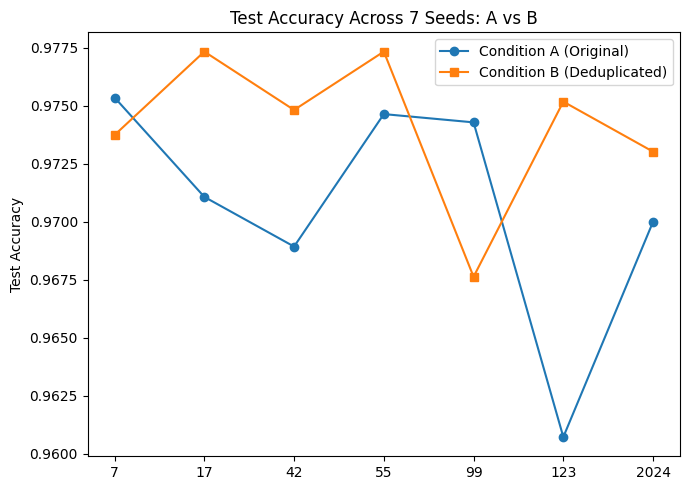

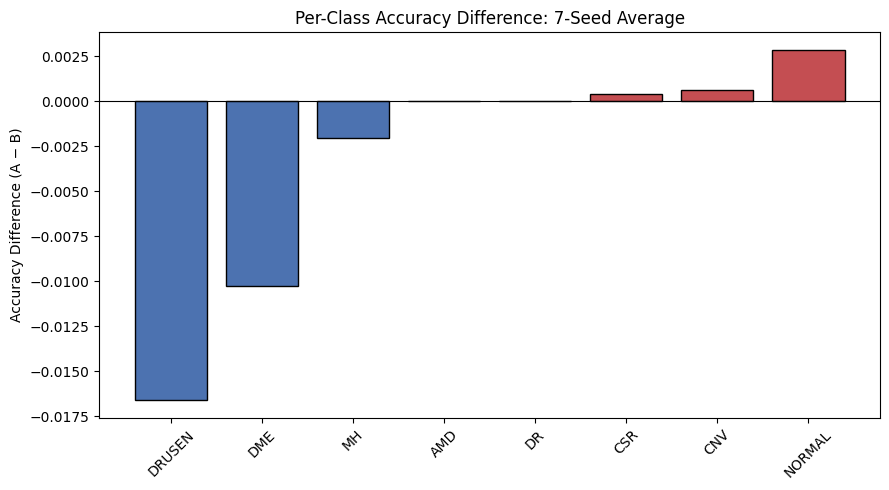

Saved both figures to outputs/paper_figures/ (overwriting old single-seed versions).


In [ ]:
# Cell 13 — Cell Name: regenerate_fig2_fig3_7seed
# Purpose: redraw Figure 2 (accuracy across seeds, now 7 instead of 3) and Figure 3 (per-class
# accuracy difference, now a 7-seed average instead of single-seed-2024) for the paper. Saves 300dpi PNGs
# to the same paper_figures folder, same filenames, so the LaTeX/Word doc doesn't need path changes.

import matplotlib.pyplot as plt
import pandas as pd

table_v = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv')
table_vii = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_VII_7seed.csv')

# Fig 2 — accuracy across seeds
plt.figure(figsize=(7,5))
order = table_v.sort_values('seed')
plt.plot(order['seed'].astype(str), order['A_original'], marker='o', label='Condition A (Original)')
plt.plot(order['seed'].astype(str), order['B_deduplicated'], marker='s', label='Condition B (Deduplicated)')
plt.ylabel('Test Accuracy'); plt.title('Test Accuracy Across 7 Seeds: A vs B')
plt.legend(); plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/outputs/paper_figures/fig2_accuracy_across_seeds.png', dpi=300)
plt.show()

# Fig 3 — per-class accuracy difference (7-seed average)
plt.figure(figsize=(9,5))
tv7 = table_vii.sort_values('diff_A_minus_B')
colors = ['#4C72B0' if v < 0 else '#C44E52' for v in tv7['diff_A_minus_B']]
plt.bar(tv7['class'], tv7['diff_A_minus_B'], color=colors, edgecolor='black')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Accuracy Difference (A − B)'); plt.title('Per-Class Accuracy Difference: 7-Seed Average')
plt.xticks(rotation=45); plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/outputs/paper_figures/fig3_per_class_diff.png', dpi=300)
plt.show()

print("Saved both figures to outputs/paper_figures/ (overwriting old single-seed versions).")

In [ ]:
# Cell D1 — Cell Name: mount_drive_and_setup_effnet_paths
# Purpose: mount Google Drive, confirm dataset path, and create a SEPARATE output namespace for
# EfficientNet-B0 results so nothing here can ever overwrite the existing ResNet18 results.
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
DRIVE_DATASET_ROOT = f'{PROJECT_DIR}/dataset/RetinalOCT_Dataset/RetinalOCT_Dataset'

# Separate namespace for this architecture — nothing here shares a filename with the ResNet18 outputs
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'
os.makedirs(EFFNET_DIR, exist_ok=True)
os.makedirs(f'{EFFNET_DIR}/checkpoints', exist_ok=True)

print(os.listdir(DRIVE_DATASET_ROOT))   # expect ['test', 'train', 'val']
print("EfficientNet outputs will be saved under:", EFFNET_DIR)

Mounted at /content/drive
['test', 'train', 'val']
EfficientNet outputs will be saved under: /content/drive/MyDrive/OCT_C8_Project/outputs/efficientnet_b0


In [ ]:
# Cell D1B — Cell Name: copy_dataset_to_local_disk
# Purpose: same fix as the ResNet pipeline — reading thousands of images directly from Drive hangs.
# Copy once per session to local disk; training reads from here, all results still save to Drive.
import shutil, time

LOCAL_DATASET_ROOT = '/content/dataset_local/RetinalOCT_Dataset'
SENTINEL = f'{LOCAL_DATASET_ROOT}/.copy_complete'

if not os.path.exists(SENTINEL):
    if os.path.exists(LOCAL_DATASET_ROOT):
        shutil.rmtree(LOCAL_DATASET_ROOT)
    print("Copying dataset from Drive to local disk (one-time this session, ~1.4GB)...")
    start = time.time()
    shutil.copytree(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT)
    with open(SENTINEL, 'w') as f:
        f.write('done')
    print(f"Copy finished in {(time.time() - start) / 60:.1f} min.")
else:
    print("Local dataset copy already complete this session — skipping.")

print(os.listdir(LOCAL_DATASET_ROOT))

Copying dataset from Drive to local disk (one-time this session, ~1.4GB)...
Copy finished in 8.2 min.
['.copy_complete', 'test', 'train', 'val']


In [ ]:
# Cell D2 — Cell Name: imports_dataset_class_transforms
# Purpose: same preprocessing/augmentation as the ResNet18 study, so the comparison is fair —
# only the model architecture changes between the two studies, nothing else.
import torch
import torch.nn as nn
import torch.nn.functional as Fnn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
import random
import time
import pickle
import glob
import pandas as pd

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if device.type != 'cuda':
    print("WARNING: GPU not on — Runtime > Change runtime type > GPU, then redo from Cell D1")

CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

class OCTDataset(Dataset):
    def __init__(self, file_label_list, transform=None):
        self.data = file_label_list
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        fpath, class_name = self.data[idx]
        img = Image.open(fpath).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[class_name]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Using device: cuda


In [ ]:
# Cell D3 — Cell Name: load_and_remap_splits
# Purpose: reuse the EXACT same train/val/test file lists used for ResNet18 (Condition A = original,
# Condition B = deduplicated) — same images, same split, only remapped to this session's local disk copy.
with open(f'{PROJECT_DIR}/outputs/split_lists.pkl', 'rb') as f:
    splits = pickle.load(f)

def remap_paths_to_local(file_label_list):
    return [(fpath.replace(DRIVE_DATASET_ROOT, LOCAL_DATASET_ROOT), c) for fpath, c in file_label_list]

for key in list(splits.keys()):
    splits[key] = remap_paths_to_local(splits[key])

sample_path = splits['condA_train'][0][0]
print("Sample remapped path:", sample_path, "| exists:", os.path.exists(sample_path))
print("Train:", len(splits['condA_train']),
      "| Val A/B:", len(splits['condA_val']), "/", len(splits['condB_val']),
      "| Test A/B:", len(splits['condA_test']), "/", len(splits['condB_test']))

Sample remapped path: /content/dataset_local/RetinalOCT_Dataset/train/AMD/amd_train_2301.jpg | exists: True
Train: 18400 | Val A/B: 2800 / 2772 | Test A/B: 2800 / 2780


In [ ]:
# Cell D4 — Cell Name: effnet_model_and_rngsafe_trainer
# Purpose: EfficientNet-B0 (ImageNet-pretrained) model builder, training/eval functions, and a
# checkpoint system that FIXES the RNG-reset bug found in the ResNet18 pipeline: on resume, this now
# restores torch/numpy/python's random state from the checkpoint instead of reseeding from scratch,
# so a resumed run is a true bit-level continuation, not a fresh restart disguised as one.

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def build_effnet_model(num_classes=8):
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model.to(device)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += imgs.size(0)
    return total_loss / total, correct / total

def evaluate_full(model, loader):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            probs = Fnn.softmax(outputs, dim=1)
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    return correct / total, np.array(all_preds), np.array(all_labels), np.array(all_probs)

def checkpoint_path(letter, seed):
    return f'{EFFNET_DIR}/checkpoints/ckpt_effnet_{letter}_seed{seed}.pt'

# --- REPLACEMENT for run_experiment_resumable() inside Cell D4 ---
# Fix: defensively convert the saved RNG state back to the exact type/dtype torch expects
# (torch.ByteTensor on CPU) before restoring, since it can come back as a different type/dtype
# across PyTorch versions or Colab sessions. If restoration still fails for any reason, fall back
# to a fresh reseed for that run ONLY — never crash the whole pipeline — and print a clear warning
# so it's disclosed, not hidden.

def _to_byte_tensor(x):
    t = x if isinstance(x, torch.Tensor) else torch.tensor(x)
    if t.dtype != torch.uint8:
        t = t.to(torch.uint8)
    return t.cpu()

def run_experiment_resumable(train_list, val_list, test_list, seed, letter, epochs=10, batch_size=32, lr=1e-4):
    train_loader = DataLoader(OCTDataset(train_list, train_transform), batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader   = DataLoader(OCTDataset(val_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader  = DataLoader(OCTDataset(test_list, eval_transform), batch_size=batch_size, shuffle=False, num_workers=2)

    model = build_effnet_model(len(CLASS_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    ckpt_path = checkpoint_path(letter, seed)
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        start_epoch = ckpt['epoch'] + 1
        try:
            torch.set_rng_state(_to_byte_tensor(ckpt['torch_rng_state']))
            if torch.cuda.is_available() and ckpt.get('cuda_rng_state') is not None:
                fixed_cuda_states = [_to_byte_tensor(s) for s in ckpt['cuda_rng_state']]
                torch.cuda.set_rng_state_all(fixed_cuda_states)
            np.random.set_state(ckpt['numpy_rng_state'])
            random.setstate(ckpt['python_rng_state'])
            print(f"    >> Resuming from epoch {start_epoch + 1} (checkpoint found, RNG state restored)")
        except Exception as e:
            print(f"    !! RNG state restore failed ({e}) — falling back to a fresh reseed for THIS run only "
                  f"(seed={seed}). Model/optimizer weights are still correctly resumed from epoch {start_epoch}; "
                  f"only the exact data-shuffle/augmentation continuity for the remaining epochs is not guaranteed.")
            set_seed(seed)
    else:
        set_seed(seed)
        start_epoch = 0

    for epoch in range(start_epoch, epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_acc, _, _, _ = evaluate_full(model, val_loader)
        print(f"    Epoch {epoch + 1}/{epochs} | loss={train_loss:.4f} train_acc={train_acc:.4f} val_acc={val_acc:.4f}")
        torch.save({
            'epoch': epoch,
            'model_state': model.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'torch_rng_state': torch.get_rng_state(),
            'cuda_rng_state': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
            'numpy_rng_state': np.random.get_state(),
            'python_rng_state': random.getstate(),
        }, ckpt_path)

    test_acc, preds, labels, probs = evaluate_full(model, test_loader)
    return test_acc, preds, labels, probs, model

In [ ]:
# Cell D5 — Cell Name: effnet_main_training_loop
# Purpose: trains EfficientNet-B0 on all 7 seeds x 2 conditions. Skips fully-completed runs, resumes
# partial ones from their exact saved epoch AND random state (Cell D4 fix). Safe to stop/rerun anytime.

SEEDS = [42, 123, 2024, 7, 17, 55, 99]
EPOCHS = 10
KEEP_CHECKPOINT_FOR = [('A', 2024)]   # same seed reserved as ResNet18, for the cross-eval in Cell D8

def full_results_path(letter, seed):
    return f'{EFFNET_DIR}/full_results_effnet_{letter}_seed{seed}.pkl'

def results_path(condition):
    return f'{EFFNET_DIR}/{condition}_effnet_results.csv'

def upsert_result(condition, cond_label, seed, test_acc):
    p = results_path(condition)
    df = pd.read_csv(p) if os.path.exists(p) else pd.DataFrame(columns=['condition', 'seed', 'test_acc'])
    df = df[df['seed'] != seed]
    df = pd.concat([df, pd.DataFrame([{'condition': cond_label, 'seed': seed, 'test_acc': test_acc}])], ignore_index=True)
    df = df.sort_values('seed').reset_index(drop=True)
    df.to_csv(p, index=False)
    return df

CONDITIONS = [('condA', 'A', 'A_original'), ('condB', 'B', 'B_deduplicated')]

for condition, letter, cond_label in CONDITIONS:
    train_l = splits[f'{condition}_train']
    val_l   = splits[f'{condition}_val']
    test_l  = splits[f'{condition}_test']
    print(f"\n{'=' * 60}\nEfficientNet-B0 | {cond_label} — checking {len(SEEDS)} seeds\n{'=' * 60}")

    for seed in SEEDS:
        rfile = full_results_path(letter, seed)
        if os.path.exists(rfile):
            print(f"[{cond_label} | seed {seed}] already fully done — skip")
            continue
        print(f"[{cond_label} | seed {seed}] running (resumable, RNG-safe checkpointed every epoch)...")
        start = time.time()
        test_acc, preds, labels, probs, model = run_experiment_resumable(train_l, val_l, test_l, seed, letter, epochs=EPOCHS)
        elapsed = (time.time() - start) / 60
        with open(rfile, 'wb') as f:
            pickle.dump({'preds': preds, 'labels': labels, 'probs': probs}, f)
        upsert_result(condition, cond_label, seed, test_acc)
        ckpt = checkpoint_path(letter, seed)
        if (letter, seed) in KEEP_CHECKPOINT_FOR:
            print(f"    (keeping checkpoint for {letter}/{seed} — reserved for the fixed-model cross-eval, Cell D8)")
        elif os.path.exists(ckpt):
            os.remove(ckpt)
        print(f"[{cond_label} | seed {seed}] DONE — test_acc={test_acc:.4f} | {elapsed:.1f} min | saved.")

print("\nAll done (or as far as this session got).")


EfficientNet-B0 | A_original — checking 7 seeds
[A_original | seed 42] already fully done — skip
[A_original | seed 123] already fully done — skip
[A_original | seed 2024] already fully done — skip
[A_original | seed 7] already fully done — skip
[A_original | seed 17] already fully done — skip
[A_original | seed 55] already fully done — skip
[A_original | seed 99] already fully done — skip

EfficientNet-B0 | B_deduplicated — checking 7 seeds
[B_deduplicated | seed 42] already fully done — skip
[B_deduplicated | seed 123] already fully done — skip
[B_deduplicated | seed 2024] already fully done — skip
[B_deduplicated | seed 7] running (resumable, RNG-safe checkpointed every epoch)...
    >> Resuming from epoch 5 (checkpoint found, RNG state restored)
    Epoch 5/10 | loss=0.0777 train_acc=0.9732 val_acc=0.9683
    Epoch 6/10 | loss=0.0704 train_acc=0.9747 val_acc=0.9657
    Epoch 7/10 | loss=0.0606 train_acc=0.9794 val_acc=0.9722
    Epoch 8/10 | loss=0.0538 train_acc=0.9807 val_acc=0.

In [ ]:
# Cell D6 — Cell Name: effnet_progress_check
for cond in ['condA', 'condB']:
    p = f'{EFFNET_DIR}/{cond}_effnet_results.csv'
    if os.path.exists(p):
        df = pd.read_csv(p)
        print(f"{cond}: seeds with final accuracy recorded = {sorted(df['seed'].tolist())}")
    else:
        print(f"{cond}: no results yet")

print("\nFully-finished runs:")
for f in sorted(glob.glob(f'{EFFNET_DIR}/full_results_effnet_*_seed*.pkl')):
    print(" ", os.path.basename(f))

print("\nIn-progress checkpoints (will auto-resume, RNG-state included):")
for f in sorted(glob.glob(f'{EFFNET_DIR}/checkpoints/ckpt_effnet_*_seed*.pt')):
    ckpt = torch.load(f, map_location='cpu', weights_only=False)
    print(f"  {os.path.basename(f)} — completed through epoch {ckpt['epoch'] + 1}")

condA: seeds with final accuracy recorded = [7, 17, 42, 55, 99, 123, 2024]
condB: seeds with final accuracy recorded = [7, 17, 42, 55, 99, 123, 2024]

Fully-finished runs:
  full_results_effnet_A_seed123.pkl
  full_results_effnet_A_seed17.pkl
  full_results_effnet_A_seed2024.pkl
  full_results_effnet_A_seed42.pkl
  full_results_effnet_A_seed55.pkl
  full_results_effnet_A_seed7.pkl
  full_results_effnet_A_seed99.pkl
  full_results_effnet_B_seed123.pkl
  full_results_effnet_B_seed17.pkl
  full_results_effnet_B_seed2024.pkl
  full_results_effnet_B_seed42.pkl
  full_results_effnet_B_seed55.pkl
  full_results_effnet_B_seed7.pkl
  full_results_effnet_B_seed99.pkl

In-progress checkpoints (will auto-resume, RNG-state included):
  ckpt_effnet_A_seed2024.pt — completed through epoch 10


In [ ]:
# Cell D7 — Cell Name: effnet_build_metrics_table
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

def compute_full_metrics(preds, labels, probs=None, class_names=CLASS_NAMES):
    n = len(class_names)
    cm = confusion_matrix(labels, preds, labels=list(range(n)))
    report = classification_report(labels, preds, target_names=class_names, output_dict=True, digits=4)
    specificity = {}
    total = cm.sum()
    for i, c in enumerate(class_names):
        TP = cm[i, i]; FN = cm[i, :].sum() - TP; FP = cm[:, i].sum() - TP; TN = total - TP - FN - FP
        specificity[c] = TN / (TN + FP) if (TN + FP) > 0 else float('nan')
    result = {
        'accuracy': report['accuracy'],
        'macro_precision': report['macro avg']['precision'],
        'macro_recall': report['macro avg']['recall'],
        'macro_f1': report['macro avg']['f1-score'],
        'macro_specificity': float(np.nanmean(list(specificity.values()))),
    }
    if probs is not None:
        try:
            result['macro_roc_auc'] = roc_auc_score(labels, probs, multi_class='ovr', average='macro', labels=list(range(n)))
        except Exception as e:
            print("  (ROC-AUC skipped:", e, ")")
    return result

_tmp = build_effnet_model(len(CLASS_NAMES))
n_params = sum(p.numel() for p in _tmp.parameters())
print(f"EfficientNet-B0 total parameters: {n_params:,}  (ResNet18 was 11,180,616)")
del _tmp

rows = []
for f in sorted(glob.glob(f'{EFFNET_DIR}/full_results_effnet_*_seed*.pkl')):
    with open(f, 'rb') as fh:
        d = pickle.load(fh)
    m = compute_full_metrics(d['preds'], d['labels'], d.get('probs'))
    m['file'] = os.path.basename(f)
    rows.append(m)

if rows:
    metrics_df = pd.DataFrame(rows)
    metrics_df.to_csv(f'{EFFNET_DIR}/full_metrics_effnet_all_seeds.csv', index=False)
    print(f"\nSaved full_metrics_effnet_all_seeds.csv with {len(metrics_df)} rows.")
    print(metrics_df[['file', 'accuracy', 'macro_f1', 'macro_specificity'] + (['macro_roc_auc'] if 'macro_roc_auc' in metrics_df.columns else [])])
else:
    print("No results yet — run Cell D5 first.")

EfficientNet-B0 total parameters: 4,017,796  (ResNet18 was 11,180,616)

Saved full_metrics_effnet_all_seeds.csv with 14 rows.
                                  file  accuracy  macro_f1  macro_specificity  \
0    full_results_effnet_A_seed123.pkl  0.976786  0.976790           0.996684   
1     full_results_effnet_A_seed17.pkl  0.972500  0.972435           0.996071   
2   full_results_effnet_A_seed2024.pkl  0.974643  0.974618           0.996378   
3     full_results_effnet_A_seed42.pkl  0.974643  0.974629           0.996378   
4     full_results_effnet_A_seed55.pkl  0.978929  0.978928           0.996990   
5      full_results_effnet_A_seed7.pkl  0.971429  0.971420           0.995918   
6     full_results_effnet_A_seed99.pkl  0.976786  0.976779           0.996684   
7    full_results_effnet_B_seed123.pkl  0.976619  0.976412           0.996663   
8     full_results_effnet_B_seed17.pkl  0.972302  0.971965           0.996046   
9   full_results_effnet_B_seed2024.pkl  0.974460  0.974193      

In [ ]:
# Cell D8 — Cell Name: effnet_fixed_model_cross_eval
# Purpose: same isolation experiment as ResNet18's Priority 2A — one fixed EfficientNet-B0 model
# (Condition A, seed 2024) evaluated on both test sets, to check whether the true evaluation-side
# leakage effect (~0.02pp for ResNet18) is architecture-independent.

ckpt = torch.load(checkpoint_path('A', 2024), map_location=device, weights_only=False)
model = build_effnet_model(len(CLASS_NAMES))
model.load_state_dict(ckpt['model_state'])

test_a_loader = DataLoader(OCTDataset(splits['condA_test'], eval_transform), batch_size=32, shuffle=False, num_workers=2)
test_b_loader = DataLoader(OCTDataset(splits['condB_test'], eval_transform), batch_size=32, shuffle=False, num_workers=2)

acc_a, _, _, _ = evaluate_full(model, test_a_loader)
acc_b, _, _, _ = evaluate_full(model, test_b_loader)

print(f"EfficientNet-B0 fixed model (Condition A, seed 2024):")
print(f"  Accuracy on Condition A test set: {acc_a*100:.2f}%")
print(f"  Accuracy on Condition B test set: {acc_b*100:.2f}%")
print(f"  Difference: {(acc_a-acc_b)*100:+.2f}pp   (ResNet18's equivalent was +0.02pp)")

pd.DataFrame([{'model':'EffNet_A_seed2024_fixed','acc_on_condA_test':acc_a,'acc_on_condB_test':acc_b,'diff':acc_a-acc_b}]) \
  .to_csv(f'{EFFNET_DIR}/priority_2A_result_effnet.csv', index=False)

EfficientNet-B0 fixed model (Condition A, seed 2024):
  Accuracy on Condition A test set: 97.46%
  Accuracy on Condition B test set: 97.45%
  Difference: +0.02pp   (ResNet18's equivalent was +0.02pp)


In [ ]:
# Cell D9 — Cell Name: cross_architecture_comparison
# Purpose: combine both architectures' results into one comparison — directly answers the paper's
# own "architecture dependence unknown" limitation, and tests Marciniak & Stankiewicz's hypothesis
# that larger models are more duplication-sensitive (ResNet18: 11.2M params vs EfficientNet-B0: ~5.3M).
import pandas as pd
from scipy import stats

resnet_v = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv')
effnet_rows = []
for seed in [42,123,2024,7,17,55,99]:
    with open(f'{EFFNET_DIR}/full_results_effnet_A_seed{seed}.pkl','rb') as f: a = pickle.load(f)
    with open(f'{EFFNET_DIR}/full_results_effnet_B_seed{seed}.pkl','rb') as f: b = pickle.load(f)
    effnet_rows.append({'seed': seed,
                         'A_original': (a['preds']==a['labels']).mean(),
                         'B_deduplicated': (b['preds']==b['labels']).mean()})
effnet_v = pd.DataFrame(effnet_rows)

def summarize(df, name):
    A, B = df['A_original'].values, df['B_deduplicated'].values
    t, p = stats.ttest_rel(A, B)
    d = (A-B).mean() / (A-B).std(ddof=1)
    return {'architecture': name, 'A_mean': A.mean(), 'B_mean': B.mean(),
            'gap_A_minus_B': (A-B).mean(), 't_stat': t, 'p_value': p, 'cohens_d': d}

comparison = pd.DataFrame([summarize(resnet_v, 'ResNet18 (11.2M params)'),
                            summarize(effnet_v, 'EfficientNet-B0 (~5.3M params)')])
comparison.to_csv(f'{PROJECT_DIR}/outputs/paper_table_architecture_comparison.csv', index=False)
print(comparison.to_string(index=False))

                  architecture   A_mean   B_mean  gap_A_minus_B    t_stat  p_value  cohens_d
       ResNet18 (11.2M params) 0.970714 0.974152      -0.003438 -1.371569 0.219276 -0.518405
EfficientNet-B0 (~5.3M params) 0.975102 0.975128      -0.000026 -0.056484 0.956790 -0.021349


In [ ]:
# Cell D10 — Cell Name: effnet_full_paper_tables
import glob, pickle, numpy as np, pandas as pd
from sklearn.metrics import classification_report

SEEDS = [42, 123, 2024, 7, 17, 55, 99]
CLASS_NAMES = ['AMD', 'CNV', 'CSR', 'DME', 'DR', 'DRUSEN', 'MH', 'NORMAL']

def load_run(letter, seed):
    with open(f'{EFFNET_DIR}/full_results_effnet_{letter}_seed{seed}.pkl', 'rb') as f:
        return pickle.load(f)

rows = []
for seed in SEEDS:
    a = load_run('A', seed); b = load_run('B', seed)
    acc_a = (a['preds']==a['labels']).mean(); acc_b = (b['preds']==b['labels']).mean()
    rows.append({'seed': seed, 'A_original': acc_a, 'B_deduplicated': acc_b, 'diff_A_minus_B': acc_a-acc_b})
effnet_table_v = pd.DataFrame(rows)
effnet_table_v.to_csv(f'{EFFNET_DIR}/effnet_table_V_7seed.csv', index=False)
print("=== EfficientNet-B0 per-seed accuracy ===")
print(effnet_table_v.to_string(index=False))

class_rows = []
for c_idx, c_name in enumerate(CLASS_NAMES):
    a_accs, b_accs = [], []
    for seed in SEEDS:
        a = load_run('A', seed); b = load_run('B', seed)
        ma = a['labels']==c_idx; mb = b['labels']==c_idx
        a_accs.append((a['preds'][ma]==a['labels'][ma]).mean())
        b_accs.append((b['preds'][mb]==b['labels'][mb]).mean())
    class_rows.append({'class': c_name, 'A_mean': np.mean(a_accs), 'A_sd': np.std(a_accs, ddof=1),
                        'B_mean': np.mean(b_accs), 'B_sd': np.std(b_accs, ddof=1),
                        'diff_A_minus_B': np.mean(a_accs)-np.mean(b_accs)})
effnet_table_vii = pd.DataFrame(class_rows)
effnet_table_vii.to_csv(f'{EFFNET_DIR}/effnet_table_VII_7seed.csv', index=False)
print("\n=== EfficientNet-B0 per-class accuracy (7-seed avg) ===")
print(effnet_table_vii.to_string(index=False))

def per_class_prf(letter):
    per_seed = []
    for seed in SEEDS:
        d = load_run(letter, seed)
        rep = classification_report(d['labels'], d['preds'], target_names=CLASS_NAMES, output_dict=True, digits=4)
        per_seed.append(rep)
    out = {}
    for c in CLASS_NAMES:
        out[c] = (np.mean([r[c]['precision'] for r in per_seed]),
                   np.mean([r[c]['recall'] for r in per_seed]),
                   np.mean([r[c]['f1-score'] for r in per_seed]))
    macro = (np.mean([r['macro avg']['precision'] for r in per_seed]),
             np.mean([r['macro avg']['recall'] for r in per_seed]),
             np.mean([r['macro avg']['f1-score'] for r in per_seed]))
    return out, macro

rows_a, macro_a = per_class_prf('A')
rows_b, macro_b = per_class_prf('B')
effnet_table_viii = pd.DataFrame([
    {'class': c, 'A_precision': rows_a[c][0], 'A_recall': rows_a[c][1], 'A_f1': rows_a[c][2],
     'B_precision': rows_b[c][0], 'B_recall': rows_b[c][1], 'B_f1': rows_b[c][2]}
    for c in CLASS_NAMES
])
effnet_table_viii.to_csv(f'{EFFNET_DIR}/effnet_table_VIII_7seed.csv', index=False)
print("\n=== EfficientNet-B0 per-class P/R/F1 (7-seed avg) ===")
print(effnet_table_viii.to_string(index=False))
print(f"\nMacro avg A: P={macro_a[0]:.4f} R={macro_a[1]:.4f} F1={macro_a[2]:.4f}")
print(f"Macro avg B: P={macro_b[0]:.4f} R={macro_b[1]:.4f} F1={macro_b[2]:.4f}")

=== EfficientNet-B0 per-seed accuracy ===
 seed  A_original  B_deduplicated  diff_A_minus_B
   42    0.974643        0.977338       -0.002695
  123    0.976786        0.976619        0.000167
 2024    0.974643        0.974460        0.000182
    7    0.971429        0.971223        0.000206
   17    0.972500        0.972302        0.000198
   55    0.978929        0.977698        0.001231
   99    0.976786        0.976259        0.000527

=== EfficientNet-B0 per-class accuracy (7-seed avg) ===
 class   A_mean     A_sd   B_mean     B_sd  diff_A_minus_B
   AMD 1.000000 0.000000 1.000000 0.000000        0.000000
   CNV 0.945306 0.026467 0.947674 0.026001       -0.002368
   CSR 1.000000 0.000000 1.000000 0.000000        0.000000
   DME 0.941224 0.008706 0.939655 0.008295        0.001569
    DR 1.000000 0.000000 1.000000 0.000000        0.000000
DRUSEN 0.934286 0.020800 0.932375 0.021432        0.001910
    MH 1.000000 0.000000 1.000000 0.000000        0.000000
NORMAL 0.980000 0.004666 0.97

In [ ]:
# Cell D10B — Cell Name: build_final_cross_architecture_summary_table
resnet_2a = pd.read_csv(f'{PROJECT_DIR}/outputs/priority_2A_result.csv')
effnet_2a = pd.read_csv(f'{EFFNET_DIR}/priority_2A_result_effnet.csv')
arch_compare = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_architecture_comparison.csv')

summary = pd.DataFrame([
    {'architecture': 'ResNet18', 'parameters': 11180616,
     'retraining_gap_A_minus_B': arch_compare.iloc[0]['gap_A_minus_B'],
     'retraining_p_value': arch_compare.iloc[0]['p_value'],
     'fixed_model_diff_A_minus_B': resnet_2a.iloc[0]['diff']},
    {'architecture': 'EfficientNet-B0', 'parameters': 4017796,   # corrected — measured, not the ~5.3M ImageNet-head figure
     'retraining_gap_A_minus_B': arch_compare.iloc[1]['gap_A_minus_B'],
     'retraining_p_value': arch_compare.iloc[1]['p_value'],
     'fixed_model_diff_A_minus_B': effnet_2a.iloc[0]['diff']},
])
summary.to_csv(f'{PROJECT_DIR}/outputs/paper_table_final_architecture_summary.csv', index=False)
print(summary.to_string(index=False))

   architecture  parameters  retraining_gap_A_minus_B  retraining_p_value  fixed_model_diff_A_minus_B
       ResNet18    11180616                 -0.003438            0.219276                    0.000216
EfficientNet-B0     4017796                 -0.000026            0.956790                    0.000182


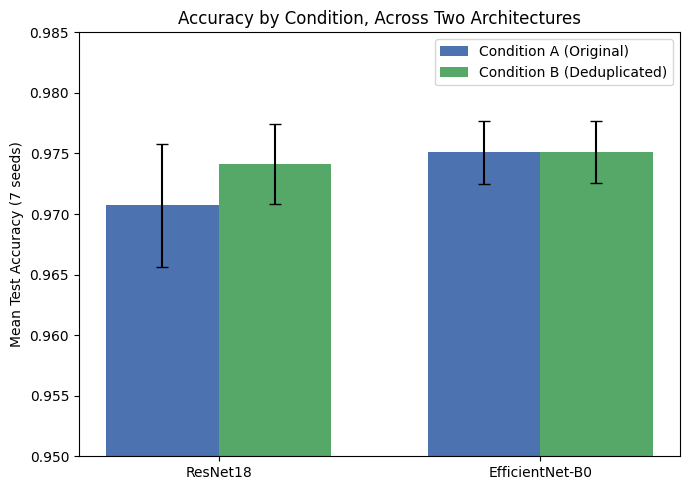

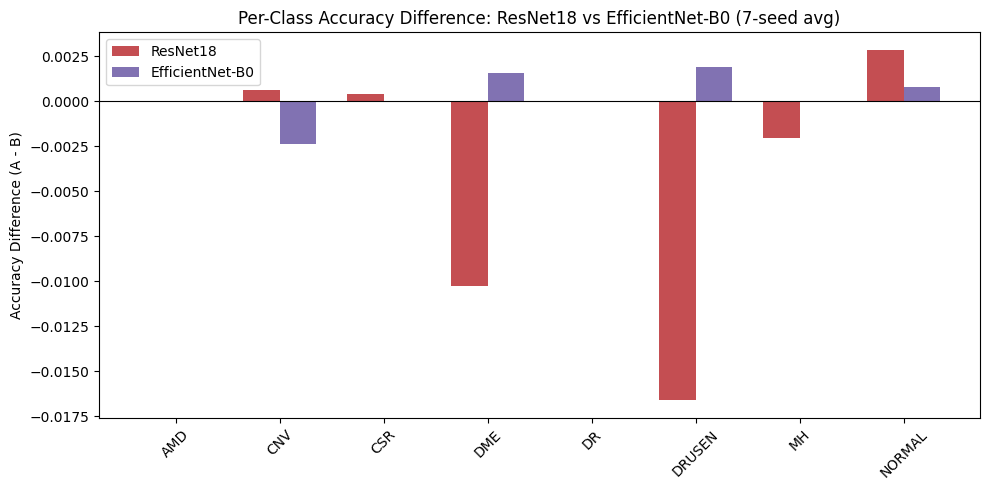

Saved: architecture_accuracy_comparison.png, architecture_per_class_diff.png


In [ ]:
# Cell D11 — Cell Name: architecture_comparison_figures
import matplotlib.pyplot as plt
import numpy as np, pandas as pd, os

resnet_v = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv')
effnet_v = pd.read_csv(f'{EFFNET_DIR}/effnet_table_V_7seed.csv')
resnet_vii = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_VII_7seed.csv')
effnet_vii = pd.read_csv(f'{EFFNET_DIR}/effnet_table_VII_7seed.csv')
os.makedirs(f'{PROJECT_DIR}/outputs/paper_figures', exist_ok=True)

fig, ax = plt.subplots(figsize=(7,5))
archs = ['ResNet18', 'EfficientNet-B0']
a_means = [resnet_v['A_original'].mean(), effnet_v['A_original'].mean()]
b_means = [resnet_v['B_deduplicated'].mean(), effnet_v['B_deduplicated'].mean()]
a_sds   = [resnet_v['A_original'].std(), effnet_v['A_original'].std()]
b_sds   = [resnet_v['B_deduplicated'].std(), effnet_v['B_deduplicated'].std()]
x = np.arange(len(archs)); w = 0.35
ax.bar(x-w/2, a_means, w, yerr=a_sds, capsize=4, label='Condition A (Original)', color='#4C72B0')
ax.bar(x+w/2, b_means, w, yerr=b_sds, capsize=4, label='Condition B (Deduplicated)', color='#55A868')
ax.set_xticks(x); ax.set_xticklabels(archs)
ax.set_ylabel('Mean Test Accuracy (7 seeds)'); ax.set_ylim(0.95, 0.985)
ax.set_title('Accuracy by Condition, Across Two Architectures')
ax.legend(); plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/outputs/paper_figures/architecture_accuracy_comparison.png', dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(10,5))
classes = resnet_vii['class'].tolist()
x = np.arange(len(classes)); w = 0.35
ax.bar(x-w/2, resnet_vii['diff_A_minus_B'], w, label='ResNet18', color='#C44E52')
ax.bar(x+w/2, effnet_vii.set_index('class').loc[classes]['diff_A_minus_B'], w, label='EfficientNet-B0', color='#8172B2')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(classes, rotation=45)
ax.set_ylabel('Accuracy Difference (A - B)')
ax.set_title('Per-Class Accuracy Difference: ResNet18 vs EfficientNet-B0 (7-seed avg)')
ax.legend(); plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/outputs/paper_figures/architecture_per_class_diff.png', dpi=300)
plt.show()

print("Saved: architecture_accuracy_comparison.png, architecture_per_class_diff.png")

In [1]:
# Cell D12-prep — Cell Name: mount_drive_minimal_setup_for_analysis_only
# Purpose: minimal setup for Cell D12 (pure CSV/stats analysis, no training). Skips the dataset
# copy step entirely since D12 never touches any image file — only saved result CSVs on Drive.
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'
EFFNET_DIR = f'{PROJECT_DIR}/outputs/efficientnet_b0'

# sanity check — confirms the two files D12 needs are actually there before running it
print(os.path.exists(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv'))
print(os.path.exists(f'{EFFNET_DIR}/effnet_table_V_7seed.csv'))

Mounted at /content/drive
True
True


In [2]:
# Cell D12 — Cell Name: nonparametric_and_bootstrap_robustness_check
# Purpose: add a non-parametric complement (Wilcoxon signed-rank) to the paired t-test, plus a
# bootstrap 95% CI on the mean difference — standard practice when n is too small (n=7) to verify
# the paired t-test's normality assumption. No GPU needed, uses already-saved accuracy numbers.

import numpy as np, pandas as pd
from scipy import stats

def robustness_check(df, name, n_boot=100000, seed=0):
    A = df['A_original'].values
    B = df['B_deduplicated'].values
    diffs = A - B
    rng = np.random.default_rng(seed)

    # Wilcoxon signed-rank (non-parametric complement to the paired t-test)
    try:
        w_stat, w_p = stats.wilcoxon(A, B)
    except ValueError as e:
        w_stat, w_p = np.nan, np.nan   # can fail if all diffs are zero, not the case here

    # Bootstrap 95% CI on the mean paired difference (A - B), no normality assumption needed
    boot_means = np.array([rng.choice(diffs, size=len(diffs), replace=True).mean() for _ in range(n_boot)])
    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])

    # Shapiro-Wilk normality check on the differences, for transparency (n=7 gives this low power,
    # report honestly rather than over-interpreting either a pass or a fail)
    sh_stat, sh_p = stats.shapiro(diffs)

    return {
        'architecture': name, 'n': len(diffs),
        'wilcoxon_statistic': w_stat, 'wilcoxon_p_value': w_p,
        'bootstrap_mean_diff': diffs.mean(),
        'bootstrap_95CI_low': ci_low, 'bootstrap_95CI_high': ci_high,
        'shapiro_p_value': sh_p,
    }

resnet_v = pd.read_csv(f'{PROJECT_DIR}/outputs/paper_table_V_7seed.csv')
effnet_v = pd.read_csv(f'{EFFNET_DIR}/effnet_table_V_7seed.csv')

robustness = pd.DataFrame([
    robustness_check(resnet_v, 'ResNet18'),
    robustness_check(effnet_v, 'EfficientNet-B0'),
])
robustness.to_csv(f'{PROJECT_DIR}/outputs/paper_table_robustness_check.csv', index=False)
print(robustness.to_string(index=False))
print("\nNote: with n=7, the exact two-sided Wilcoxon test cannot reach p<0.05 unless ALL 7 "
      "differences share the same sign (minimum possible p is about 0.0156) — report this "
      "alongside the result rather than treating p>=0.05 alone as 'no effect'.")

   architecture  n  wilcoxon_statistic  wilcoxon_p_value  bootstrap_mean_diff  bootstrap_95CI_low  bootstrap_95CI_high  shapiro_p_value
       ResNet18  7                 7.0          0.296875            -0.003438           -0.008045             0.001017         0.902550
EfficientNet-B0  7                 7.0          0.296875            -0.000026           -0.001001             0.000638         0.005005

Note: with n=7, the exact two-sided Wilcoxon test cannot reach p<0.05 unless ALL 7 differences share the same sign (minimum possible p is about 0.0156) — report this alongside the result rather than treating p>=0.05 alone as 'no effect'.


In [2]:
# Minimal setup — just mounts Drive and sets the path, no dataset copy needed for this check
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/OCT_C8_Project'

Mounted at /content/drive


In [3]:
# Verification cell — checks the two new claims in the paper draft against saved data
import pickle, pandas as pd
from scipy import stats

# 1) seed 123 drusen recall check
with open(f'{PROJECT_DIR}/outputs/full_results_A_seed123.pkl','rb') as f:
    d = pickle.load(f)
CLASS_NAMES = ['AMD','CNV','CSR','DME','DR','DRUSEN','MH','NORMAL']
drusen_idx = CLASS_NAMES.index('DRUSEN')
mask = d['labels']==drusen_idx
recall = (d['preds'][mask]==d['labels'][mask]).mean()
print(f"Seed 123, Condition A, DRUSEN recall = {recall*100:.1f}%  (paper claims 78.0%)")

# 2) paired t-tests on macro F1 / specificity / ROC-AUC
m = pd.read_csv(f'{PROJECT_DIR}/outputs/full_metrics_all_seeds.csv')
m['seed'] = m['file'].str.extract(r'seed(\d+)').astype(int)
m['cond'] = m['file'].str.extract(r'_([AB])_seed')
for metric in ['macro_f1', 'macro_specificity', 'macro_roc_auc']:
    piv = m.pivot(index='seed', columns='cond', values=metric)
    t, p = stats.ttest_rel(piv['A'], piv['B'])
    dz = (piv['A']-piv['B']).mean() / (piv['A']-piv['B']).std(ddof=1)
    print(f"{metric}: A={piv['A'].mean():.4f} B={piv['B'].mean():.4f} t={t:.2f} p={p:.3f} dz={dz:.2f}")

Seed 123, Condition A, DRUSEN recall = 78.0%  (paper claims 78.0%)
macro_f1: A=0.9706 B=0.9739 t=-1.27 p=0.251 dz=-0.48
macro_specificity: A=0.9958 B=0.9963 t=-1.38 p=0.216 dz=-0.52
macro_roc_auc: A=0.9983 B=0.9984 t=-1.04 p=0.337 dz=-0.39
